# 03 · Supplemental: matched SNP-level verification of triple regions, outdoor overlap, concordance classes

SNP-level sections (2-5) run over the **triple regions** from notebook 02: the scan footprint (first scan position − 50 kb to last + 50 kb) of the triple windows (≥ 3 of the 4 panels at their own 95th percentile, any combination), with peaks ≤ 500 kb apart merged (the 2L Consensus region). Regions, not 50 kb windows, are the unit, so these results do not move when the 50 kb sampling grid shifts. Every panel's own per-sample allele frequencies are used (LC50-DSPR-I, LC90-DSPR-I, LC50-DSPR-O VCFs; LC50-DGRP-I allele-frequency table). Panel comparisons are matched so each one changes a single factor:

| Contrast | Panel A | Panel B | What differs |
|---|---|---|---|
| Population | LC50-DSPR-I | LC50-DGRP-I | founder population (same dose, indoor) |
| Environment | LC50-DSPR-I | LC50-DSPR-O | indoor vs outdoor (same dose, DSPR) |
| Dose | LC50-DSPR-I | LC90-DSPR-I | LC50 vs LC90 (DSPR, indoor) |
| Outdoor E&R | LC50-DSPR-O | outdoor E vs S | xQTL vs evolve-and-resequence (both outdoor) |

`ARM_KEEP` restricts sections 2-5 to one arm (e.g. `"2L"`); `NULL` (default) = every triple region on every arm. Sections 6-8 are genome-wide and ignore it. Thresholds = each panel's own 95th percentile. Outdoor = primary track `pooled`, 50 kb, median |z|. ΔAF = selected − control everywhere (xQTL: T − C; outdoor: E − S).

### Inputs → outputs

| In | Out (`Final_Final_Data/`) |
|---|---|
| `Data/01_GLM/conc_50kb.csv` | `Data/03_Supplemental/region_dAF_permutation.csv` |
| `Data/01_GLM/rudflies_2023_SvE_GLM_SNP.tsv` (per-tpt dAF) | `Data/03_Supplemental/dgrp_vs_dspr_site_overlap.csv` |
| `Data/02_Peaks/triple_overlap_windows.csv`, `triple_regions.csv` | `Data/03_Supplemental/matched_contrast_dAF_sites.csv`, `matched_contrast_dAF_stats.csv` |
| `Data/02_Peaks/triple_region_AF_{dspr3,dspr4,outspino3,dgrp}.csv` | `Data/03_Supplemental/outdoor_dAF_triple_regions_empirical.csv` |
| `Data/02_Peaks/triple_region_snp_af.csv` | `Data/03_Supplemental/outdoor_95th_overlap_windows.csv` (→ notebook 04) |
| `Data/02_Peaks/dmel_gene_coords.csv` | `Data/03_Supplemental/concordance_classes/…` (annotated windows, per-class windows + genes, counts) |
| `Final_Data_Inputs/xQTL/Phenotypic_Data/XQTL_Record.csv` | `Figures/03_Supplemental/*.png` (listed in each cell) |

## 1. Setup

In [23]:
ROOT    <- "D:/xQTL_2025_Data/Final_Window_Analysis/Analysis_jupyter_notebooks/Final_Notebooks"
IN_DIR  <- file.path(ROOT, "Final_Data_Inputs")
OUT_DIR <- file.path(ROOT, "Final_Final_Data")
D_GLM   <- file.path(OUT_DIR, "Data", "01_GLM")
D_PK    <- file.path(OUT_DIR, "Data", "02_Peaks")
DATA    <- file.path(OUT_DIR, "Data",    "03_Supplemental")
FIGS    <- file.path(OUT_DIR, "Figures", "03_Supplemental")
CLS_DIR <- file.path(DATA, "concordance_classes")
for (d in c(DATA, FIGS, CLS_DIR)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(OUT_DIR)

ARM_KEEP <- NULL                 # NULL = all triple windows; e.g. "2L" to restrict sections 2-5
Q_CUT    <- 0.95
qcut     <- function(v) unname(quantile(v, Q_CUT, na.rm = TRUE))
WIN      <- 50000
SCAN_HALF  <- 50000              # X-QTL scan half-width: value at pos summarizes pos +/- 50 kb (same as 02)
POS_OFFSET <- WIN / 2            # notebook 01 POS_IS = "center": scan position = win_start + 25 kb
PRIMARY  <- "pooled"
OUT_STAT <- "median"
MIN_MAF  <- 0.05                 # same site filter as notebook 02 (folded mean AF within panel)
NPERM    <- 10000                 # label permutations per panel
HI_AF    <- 0.1                  # site-overlap section: mean control AF > HI_AF
N_NULL_WINDOWS <- 100            # random background 50 kb windows pooled for the violin (display only)
N_BG           <- 10000          # random same-length background intervals per region (section 5 test)
MIN_SNP_WIN    <- 5              # background windows / intervals need >= this many SNPs
CHROMS   <- c("2L", "2R", "3L", "3R", "X")
set.seed(1)

suppressPackageStartupMessages({
  library(tidyverse); library(data.table); library(patchwork)
  library(GenomicRanges); library(IRanges)
  library(gridExtra); library(grid); library(gtable); library(scales)
})

PANELS <- c(z_dgrp = "LC50-DGRP-I", z_dspr3 = "LC50-DSPR-I", z_dspr4 = "LC90-DSPR-I", z_outspino3 = "LC50-DSPR-O")
SNP_PANELS <- c("z_dspr3", "z_dgrp", "z_dspr4", "z_outspino3")      # display order: reference first, as in the main figures
strip_chr <- function(x) sub("^chr", "", x)
## ---- publication style shared by every figure (main + supplement) --------
SUP_RED     <- "#D2232A"; SUP_BLUE <- "#0057B8"
PANEL_ORDER <- c("z_dspr3", "z_dgrp", "z_dspr4", "z_outspino3")      # reference (LC50-DSPR-I) first
PANEL_COL   <- c("LC50-DSPR-I" = "#457b9d", "LC50-DGRP-I" = "#9d4edd", "LC90-DSPR-I" = "#2a9d8f",
                 "LC50-DSPR-O" = "#E9A23B", "Outdoor E&R" = "#6c757d")
W_FULL <- 180 / 25.4; W_HALF <- 85 / 25.4
mm     <- function(x) x / 25.4
theme_pub <- function(base = 8) {
  theme_classic(base_size = base) +
    theme(axis.line = element_line(linewidth = 0.3), axis.ticks = element_line(linewidth = 0.3),
          axis.ticks.length = unit(2, "pt"), axis.text = element_text(size = 7, colour = "black"),
          axis.title = element_text(size = 8),
          strip.background = element_blank(), strip.text = element_text(size = 7, face = "bold", hjust = 0),
          legend.title = element_text(size = 6.5, face = "bold"), legend.text = element_text(size = 6),
          legend.key.size = unit(7, "pt"), legend.margin = margin(0, 0, 0, 0),
          plot.title = element_text(size = 8, face = "bold"),
          plot.subtitle = element_text(size = 6.5, colour = "grey30"),
          plot.margin = margin(4, 6, 4, 4))
}
TAG_THEME <- theme(plot.tag = element_text(size = 10, face = "bold"))
save_pub <- function(p, name, w = W_FULL, h, dpi = 600) {
  ggsave(file.path(FIGS, paste0(name, ".png")), p, width = w, height = h, dpi = dpi, bg = "white", limitsize = FALSE)
  ggsave(file.path(FIGS, paste0(name, ".pdf")), p, width = w, height = h, device = cairo_pdf, limitsize = FALSE)
  options(repr.plot.width = w * 1.5, repr.plot.height = h * 1.5)
  invisible(p)
}


save_table_png <- function(disp, title, file, foot = NULL, italic_col = NULL, fontsize = 7) {
  th <- ttheme_minimal(
    core    = list(fg_params = list(hjust = 0, x = 0.05, fontsize = fontsize),
                   bg_params = list(fill = c("white", "grey95"), col = NA)),
    colhead = list(fg_params = list(fontface = "bold", hjust = 0, x = 0.05, fontsize = fontsize + 1, col = "white"),
                   bg_params = list(fill = SUP_BLUE, col = NA)))
  tg <- tableGrob(disp, rows = NULL, theme = th)
  if (!is.null(italic_col)) {
    sel <- tg$layout$name == "core-fg" & tg$layout$l == which(colnames(disp) == italic_col)
    tg$grobs[sel] <- lapply(tg$grobs[sel], function(gr) { gr$gp$font <- 3L; gr })
  }
  tit <- textGrob(title, gp = gpar(fontface = "bold", fontsize = 9))
  tab <- gtable_add_rows(tg, heights = grobHeight(tit) + unit(6, "mm"), pos = 0)
  tab <- gtable_add_grob(tab, tit, t = 1, l = 1, r = ncol(tg), clip = "off")
  if (!is.null(foot)) {
    ft  <- textGrob(foot, x = 0.01, hjust = 0, gp = gpar(fontsize = 6, col = "grey40", fontface = "italic"))
    tab <- gtable_add_rows(tab, heights = grobHeight(ft) + unit(4, "mm"), pos = -1)
    tab <- gtable_add_grob(tab, ft, t = nrow(tab), l = 1, r = ncol(tab), clip = "off")
  }
  pdf(NULL)
  gw <- max(convertWidth(sum(tab$widths), "in", valueOnly = TRUE),
            convertWidth(grobWidth(tit), "in", valueOnly = TRUE))
  gh <- convertHeight(sum(tab$heights), "in", valueOnly = TRUE)
  dev.off()
  png(file, width = gw + 0.8, height = gh + 0.8, units = "in", res = 300, bg = "white")
  grid.newpage(); pushViewport(viewport(width = unit(gw, "in"), height = unit(gh, "in")))
  grid.draw(tab); popViewport(); dev.off()
  grid.newpage(); grid.draw(tab)
  invisible(tab)
}

## ---- inputs from 01 / 02 -------------------------------------------------
conc50      <- read.csv(file.path(D_GLM, "conc_50kb.csv")) %>% mutate(chr = as.character(chr))
triple_all  <- read.csv(file.path(D_PK, "triple_overlap_windows.csv")) %>% mutate(chr = as.character(chr))
regions_all <- read.csv(file.path(D_PK, "triple_regions.csv")) %>% mutate(chr = as.character(chr))
gene_coords <- as_tibble(read.csv(file.path(D_PK, "dmel_gene_coords.csv"), stringsAsFactors = FALSE))

keep_arm <- function(df, col = "chr") if (is.null(ARM_KEEP)) df else df[df[[col]] %in% ARM_KEEP, , drop = FALSE]
triple_windows <- keep_arm(triple_all)
triple_regions <- keep_arm(regions_all)
stopifnot(nrow(triple_regions) > 0)

af_tri <- lapply(setNames(SNP_PANELS, SNP_PANELS), function(zc) {
  f <- file.path(D_PK, sprintf("triple_region_AF_%s.csv", sub("^z_", "", zc)))
  if (!file.exists(f)) { message("no per-sample AF for ", PANELS[[zc]], " (", basename(f), ")"); return(NULL) }
  d <- fread(f)[, chr := as.character(chr)]
  d[region %in% triple_regions$region]
})
af_tri <- af_tri[!vapply(af_tri, is.null, logical(1))]
peak_snps <- fread(file.path(D_PK, "triple_region_snp_af.csv"))[, chr := as.character(chr)][
  region %in% triple_regions$region]
peak_snps[REF == "", REF := NA_character_][ALT == "", ALT := NA_character_]   # fread reads written NAs back as ""

glm_hdr  <- names(fread(file.path(D_GLM, "rudflies_2023_SvE_GLM_SNP.tsv"), nrows = 0))
DAF_LAST <- tail(sort(grep("^dAF_t", glm_hdr, value = TRUE)), 1)          # last timepoint E - S
out_snp  <- fread(file.path(D_GLM, "rudflies_2023_SvE_GLM_SNP.tsv"), select = c("CHROM", "POS", DAF_LAST))
setnames(out_snp, DAF_LAST, "delta")
out_snp[, CHROM := strip_chr(as.character(CHROM))]
out_snp <- out_snp[is.finite(delta)]
## numeric coordinates everywhere, so the non-equi joins below never hit an integer / double mismatch
out_snp[, POS := as.numeric(POS)]
num_coords <- function(df) mutate(df, across(any_of(c("win_start", "win_end", "start", "end", "fp_start", "fp_end")), as.numeric))
conc50 <- num_coords(conc50); triple_all <- num_coords(triple_all); regions_all <- num_coords(regions_all)
triple_windows <- num_coords(triple_windows); triple_regions <- num_coords(triple_regions)

reg_levels <- triple_regions %>% arrange(match(chr, CHROMS), fp_start) %>%
  mutate(lab = sprintf("%s (%s %.2f-%.2f Mb)", region, chr, fp_start / 1e6, fp_end / 1e6))
cat(sprintf("SNP-level scope: %s | %d triple regions (%d triple windows) on %s | outdoor dAF column: %s\n",
            if (is.null(ARM_KEEP)) "all arms" else paste(ARM_KEEP, collapse = ","),
            nrow(triple_regions), nrow(triple_windows), paste(unique(triple_regions$chr), collapse = ", "), DAF_LAST))
print(as_tibble(reg_levels) %>% dplyr::select(region, lab, span_kb, peaks, hit_sets, top_panel), width = Inf)
for (zc in names(af_tri))
  cat(sprintf("  %-12s %6d sites | %d T, %d C samples\n", PANELS[[zc]], nrow(af_tri[[zc]]),
              length(grep("^T_", names(af_tri[[zc]]))), length(grep("^C_", names(af_tri[[zc]])))))

SNP-level scope: all arms | 4 triple regions (8 triple windows) on 2L, 2R, 3L | outdoor dAF column: dAF_t4
# A tibble: 4 × 6
  region       lab                              span_kb peaks              
  <chr>        <chr>                              <int> <chr>              
1 2L_Consensus 2L_Consensus (2L 13.56-14.31 Mb)     750 2L_1,2L_2,2L_3,2L_4
2 2R_1         2R_1 (2R 13.47-13.57 Mb)             100 2R_1               
3 3L_1         3L_1 (3L 6.18-6.28 Mb)               100 3L_1               
4 3L_2         3L_2 (3L 18.03-18.13 Mb)             100 3L_2               
  hit_sets                  top_panel  
  <chr>                     <chr>      
1 DGRP+I90+O50; I50+I90+O50 LC90-DSPR-I
2 I50+I90+O50               LC50-DSPR-I
3 DGRP+I90+O50              LC50-DSPR-O
4 DGRP+I50+O50              LC50-DSPR-I
  LC50-DSPR-I   21093 sites | 8 T, 8 C samples
  LC50-DGRP-I   39166 sites | 8 T, 8 C samples
  LC90-DSPR-I   21650 sites | 8 T, 8 C samples
  LC50-DSPR-O   20701 sites | 5 T, 5 C

## 2. ΔAF in each triple region vs a label-permutation null, every panel

Per panel and region: mean |ΔAF| over sites passing `MIN_MAF`. Null: shuffle that panel's sample labels (group sizes kept) `NPERM` times; the same shuffle hits every region of the panel. One-sided p, BH across regions within panel. Each panel is tested on its own samples, so a real region should stand out in the panels that make up its hit set, and the remaining panel shows whether the signal extends there.

Data: `region_dAF_permutation.csv`. Figure: `region_dAF_permutation.png`.

# A tibble: 16 × 7
   panel       region       n_sites obs_mean_absdAF null_mean   p_perm     p_BH
   <fct>       <chr>          <int>           <dbl>     <dbl>    <dbl>    <dbl>
 1 LC50-DSPR-I 2L_Consensus   10340          0.0241   0.0263  0.776    0.886   
 2 LC50-DSPR-I 2R_1            2097          0.0269   0.0265  0.318    0.680   
 3 LC50-DSPR-I 3L_1            1227          0.0223   0.0240  0.886    0.886   
 4 LC50-DSPR-I 3L_2            1785          0.0248   0.0247  0.340    0.680   
 5 LC50-DGRP-I 2L_Consensus   14758          0.0114   0.00797 0.00710  0.00710 
 6 LC50-DGRP-I 2R_1            2889          0.0135   0.00811 0.00110  0.00147 
 7 LC50-DGRP-I 3L_1            1452          0.0173   0.00877 0.000200 0.000400
 8 LC50-DGRP-I 3L_2            2061          0.0165   0.00835 0.000200 0.000400
 9 LC90-DSPR-I 2L_Consensus   10676          0.0504   0.0278  0.000100 0.000400
10 LC90-DSPR-I 2R_1            2154          0.0360   0.0284  0.000400 0.000800
11 LC90-DSPR-I 3L_1  

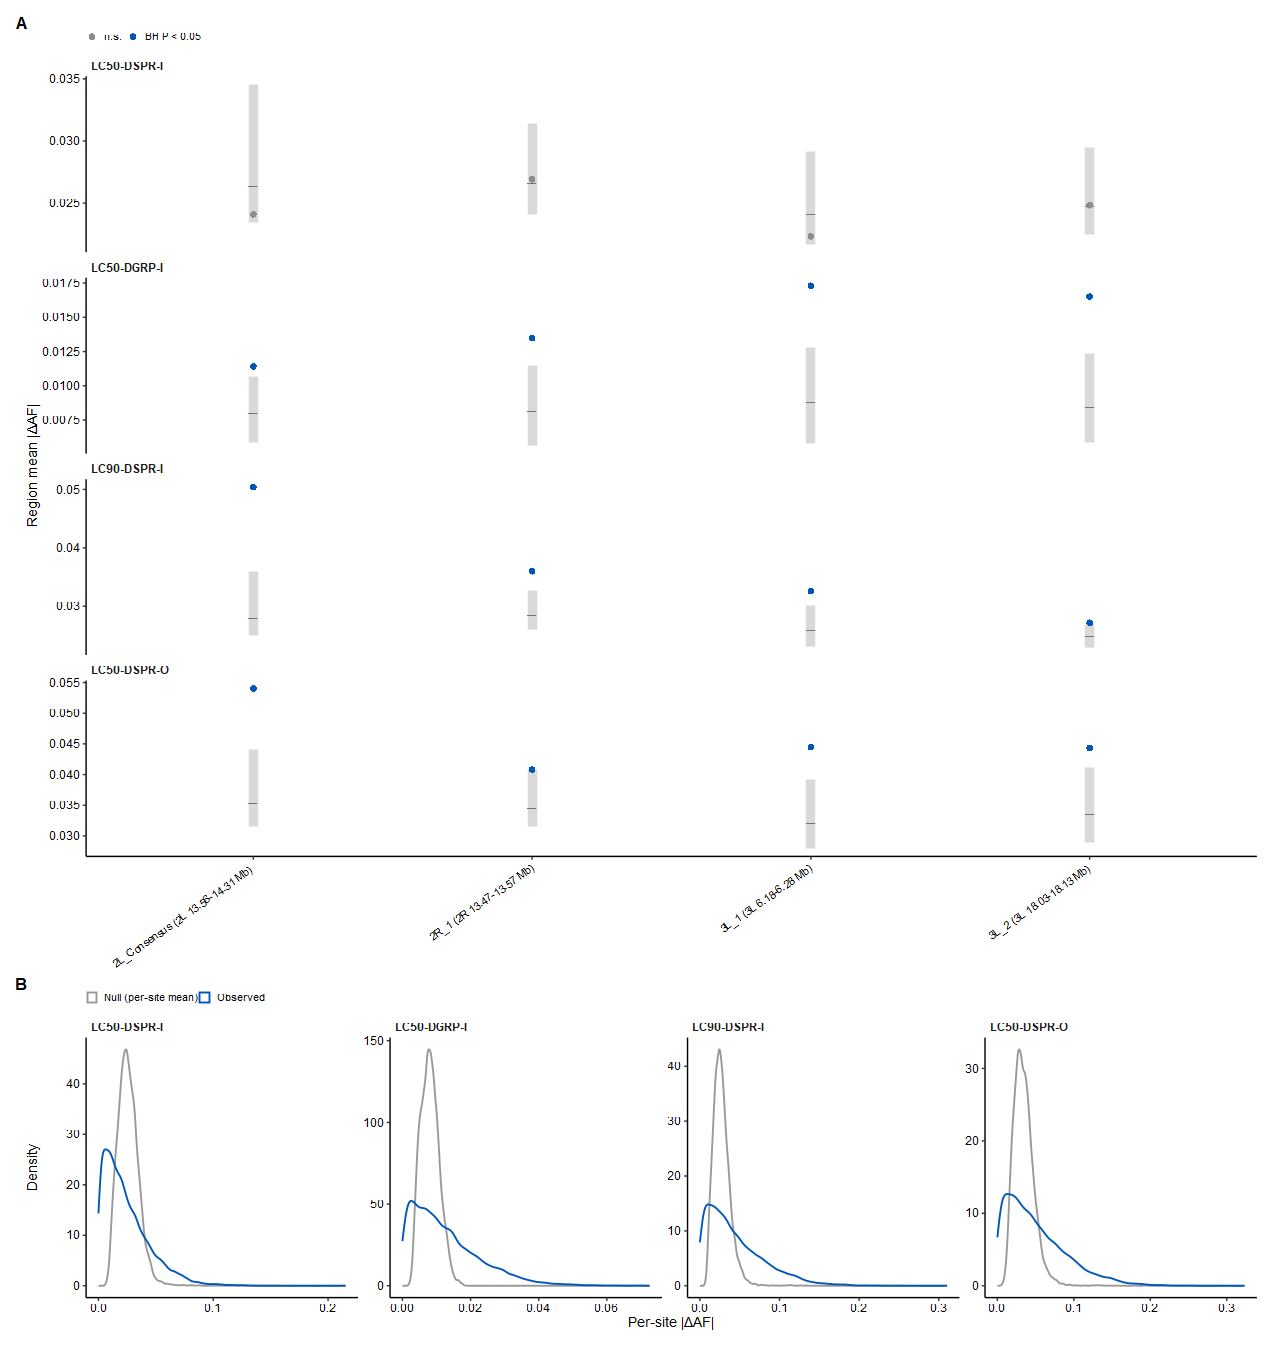

In [24]:
perm_panel <- function(zc) {
  d  <- af_tri[[zc]]
  Tm <- as.matrix(d[, grep("^T_", names(d), value = TRUE), with = FALSE])
  Cm <- as.matrix(d[, grep("^C_", names(d), value = TRUE), with = FALSE])
  Y  <- cbind(Tm, Cm); isT <- seq_len(ncol(Y)) <= ncol(Tm)
  m  <- rowMeans(Y)
  ok <- complete.cases(Y) & pmin(m, 1 - m) >= MIN_MAF
  Y  <- Y[ok, , drop = FALSE]
  wid <- droplevels(factor(d$region[ok], levels = reg_levels$region))
  n_w <- as.vector(table(wid))
  obs <- abs(rowMeans(Y[, isT, drop = FALSE]) - rowMeans(Y[, !isT, drop = FALSE]))
  obs_win <- as.vector(rowsum(obs, wid, reorder = TRUE)) / n_w
  perm <- matrix(NA_real_, NPERM, nlevels(wid)); acc <- numeric(nrow(Y))
  for (p in seq_len(NPERM)) {
    ti <- sample(ncol(Y), sum(isT))
    dp <- abs(rowMeans(Y[, ti, drop = FALSE]) - rowMeans(Y[, -ti, drop = FALSE]))
    acc <- acc + dp
    perm[p, ] <- as.vector(rowsum(dp, wid, reorder = TRUE)) / n_w
  }
  kept <- reg_levels[match(levels(wid), reg_levels$region), ]
  list(res = kept %>% dplyr::select(region, lab) %>%
         mutate(panel = PANELS[[zc]], n_T = sum(isT), n_C = sum(!isT), n_sites = n_w,
                obs_mean_absdAF = obs_win, null_mean = colMeans(perm),
                null_lo = apply(perm, 2, quantile, 0.025), null_hi = apply(perm, 2, quantile, 0.975),
                p_perm = (colSums(sweep(perm, 2, obs_win, ">=")) + 1) / (NPERM + 1),
                p_BH = p.adjust(p_perm, "BH")),
       site = tibble(panel = PANELS[[zc]], observed = obs, null = acc / NPERM))
}
perm_all <- lapply(names(af_tri), perm_panel)
perm_res <- as_tibble(bind_rows(lapply(perm_all, `[[`, "res"))) %>%
  mutate(panel = factor(panel, levels = PANELS[SNP_PANELS]), lab = factor(lab, levels = reg_levels$lab))
write.csv(perm_res, file.path(DATA, "region_dAF_permutation.csv"), row.names = FALSE)
print(perm_res %>% dplyr::select(panel, region, n_sites, obs_mean_absdAF, null_mean, p_perm, p_BH), n = Inf)

p_win <- ggplot(perm_res, aes(lab, obs_mean_absdAF)) +
  geom_linerange(aes(ymin = null_lo, ymax = null_hi), colour = "grey85", linewidth = 2) +
  geom_point(aes(y = null_mean), colour = "grey45", shape = 95, size = 3) +
  geom_point(aes(colour = p_BH < 0.05), size = 1.6, stroke = 0) +
  scale_colour_manual(values = c(`TRUE` = SUP_BLUE, `FALSE` = "grey55"),
                      labels = c(`TRUE` = "BH P < 0.05", `FALSE` = "n.s."), name = NULL) +
  facet_wrap(~ panel, ncol = 1, scales = "free_y") +
  labs(x = NULL, y = "Region mean |\u0394AF|") +
  theme_pub() +
  theme(axis.text.x = element_text(size = 6, angle = 35, hjust = 1), legend.position = "top",
        legend.justification = "left", panel.spacing.y = unit(3, "pt"))
p_site <- bind_rows(lapply(perm_all, `[[`, "site")) %>%
  pivot_longer(c(observed, null), names_to = "set", values_to = "value") %>%
  mutate(panel = factor(panel, levels = PANELS[SNP_PANELS]),
         set = factor(set, levels = c("null", "observed"), labels = c("Null (per-site mean)", "Observed"))) %>%
  ggplot(aes(value, colour = set)) + geom_density(linewidth = 0.4) +
  facet_wrap(~ panel, nrow = 1, scales = "free") +
  scale_colour_manual(values = c("Null (per-site mean)" = "grey60", "Observed" = SUP_BLUE), name = NULL) +
  scale_x_continuous(breaks = scales::breaks_pretty(3)) +
  labs(x = "Per-site |\u0394AF|", y = "Density") +
  theme_pub() + theme(legend.position = "top", legend.justification = "left")
fig_perm <- (p_win / p_site) + plot_layout(heights = c(3, 1)) +
  plot_annotation(tag_levels = "A") & TAG_THEME
save_pub(fig_perm, "region_dAF_permutation", h = mm(190))
fig_perm

## 3. LC50-DGRP-I site overlap with each DSPR panel

Higher-frequency sites (mean control AF > `HI_AF` within each panel), shared = same chr:pos. LC50-DSPR-I is the matched comparison (same dose, indoor); the other two DSPR panels are shown for reference.

Data: `dgrp_vs_dspr_site_overlap.csv`. Figure: `dgrp_vs_dspr_site_overlap_table.png`.

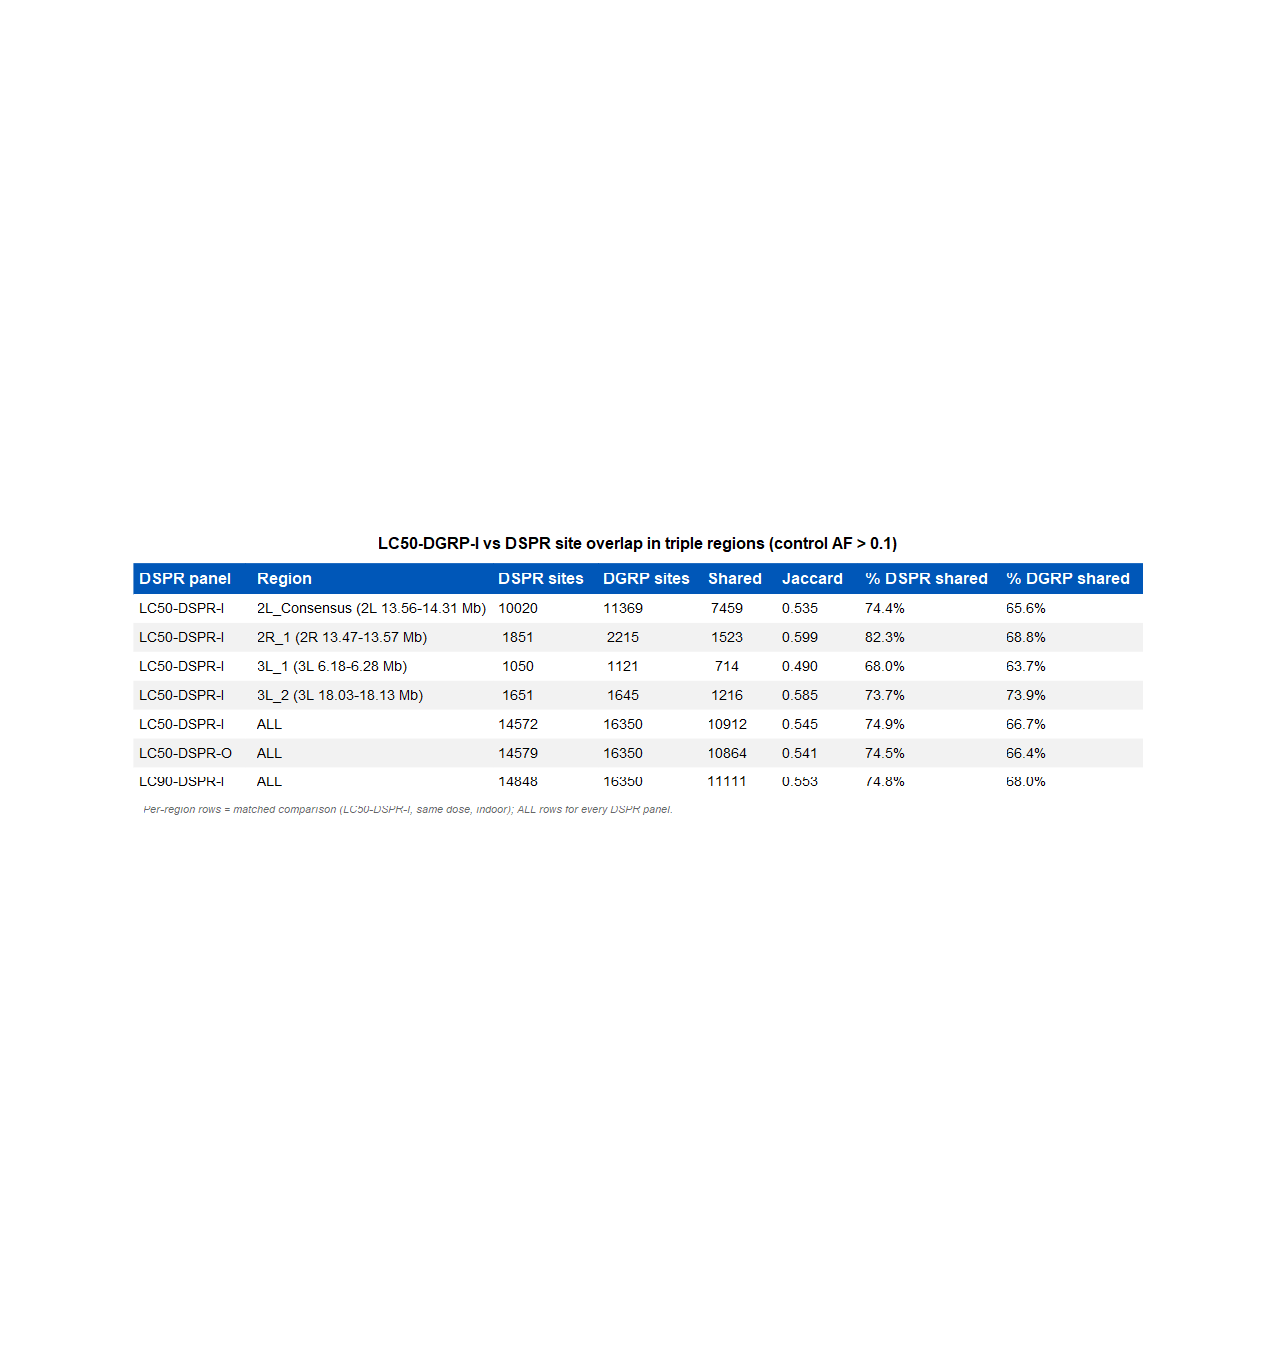

In [25]:
hi_keys <- function(zc) {
  d <- af_tri[[zc]]; Cm <- as.matrix(d[, grep("^C_", names(d), value = TRUE), with = FALSE])
  d[rowMeans(Cm, na.rm = TRUE) > HI_AF, .(region, key = paste(chr, POS, sep = ":"))]
}
stopifnot("z_dgrp" %in% names(af_tri))
dg <- hi_keys("z_dgrp")
ov_stats <- function(kp, kv) {
  s <- length(intersect(kp, kv)); u <- length(union(kp, kv))
  tibble(dspr_sites = length(kp), dgrp_sites = length(kv), shared = s, union = u,
         jaccard = ifelse(u > 0, s / u, NA_real_),
         pct_dspr_shared = ifelse(length(kp) > 0, s / length(kp), NA_real_),
         pct_dgrp_shared = ifelse(length(kv) > 0, s / length(kv), NA_real_))
}
site_ov <- bind_rows(lapply(intersect(c("z_dspr3", "z_dspr4", "z_outspino3"), names(af_tri)), function(zc) {
  ds <- hi_keys(zc)
  bind_rows(
    lapply(seq_len(nrow(reg_levels)), function(i) {
      w <- reg_levels$region[i]
      bind_cols(dspr_panel = PANELS[[zc]], window = reg_levels$lab[i],
                ov_stats(ds$key[ds$region == w], dg$key[dg$region == w]))
    }),
    bind_cols(dspr_panel = PANELS[[zc]], window = "ALL", ov_stats(ds$key, dg$key)))
})) %>% mutate(matched = dspr_panel == "LC50-DSPR-I")
write.csv(site_ov, file.path(DATA, "dgrp_vs_dspr_site_overlap.csv"), row.names = FALSE)

disp <- site_ov %>% filter(matched | window == "ALL") %>%
  arrange(desc(matched), dspr_panel, window == "ALL") %>%
  transmute(`DSPR panel` = dspr_panel, Region = window, `DSPR sites` = dspr_sites, `DGRP sites` = dgrp_sites,
            Shared = shared, Jaccard = ifelse(is.na(jaccard), "-", sprintf("%.3f", jaccard)),
            `% DSPR shared` = ifelse(is.na(pct_dspr_shared), "-", percent(pct_dspr_shared, accuracy = 0.1)),
            `% DGRP shared` = ifelse(is.na(pct_dgrp_shared), "-", percent(pct_dgrp_shared, accuracy = 0.1)))
save_table_png(disp, sprintf("LC50-DGRP-I vs DSPR site overlap in triple regions (control AF > %.1f)", HI_AF),
               file.path(FIGS, "dgrp_vs_dspr_site_overlap_table.png"), fontsize = 8,
               foot = "Per-region rows = matched comparison (LC50-DSPR-I, same dose, indoor); ALL rows for every DSPR panel.")

## 4. Matched ΔAF contrasts at shared sites

For each one-factor contrast: sites present (and passing `MIN_MAF`) in both datasets, ΔAF of A vs ΔAF of B. Alleles are aligned before comparison: sites where REF / ALT are swapped between datasets have ΔAF of B sign-flipped, sites with different alleles are dropped (outdoor E&R has no REF / ALT, so that contrast is unchecked). Spearman ρ and sign agreement (fraction of shared sites where both move the same direction), overall and per region. Sites within a region are linked, so treat ρ / sign agreement as effect sizes; the per-region permutation tests in section 2 carry the inference.

Data: `matched_contrast_dAF_sites.csv`, `matched_contrast_dAF_stats.csv`. Figures: `matched_contrast_dAF_scatter.png`, `dAF_all_panels_triple_regions.png`.

allele alignment per contrast:
# A tibble: 4 × 4
  contrast                                unchecked mismatch  same
  <fct>                                       <int>    <int> <int>
1 Population: LC50-DSPR-I vs LC50-DGRP-I      12365       NA    NA
2 Environment: LC50-DSPR-I vs LC50-DSPR-O        NA        8 14827
3 Dose: LC50-DSPR-I vs LC90-DSPR-I               NA       10 15160
4 Outdoor: LC50-DSPR-O vs outdoor E&R         12109       NA    NA
# A tibble: 20 × 5
   contrast                                region   n_shared      rho sign_agree
   <fct>                                   <chr>       <int>    <dbl>      <dbl>
 1 Population: LC50-DSPR-I vs LC50-DGRP-I  ALL         12365 -0.0412       0.485
 2 Population: LC50-DSPR-I vs LC50-DGRP-I  2L_Cons…     8287 -0.0337       0.484
 3 Population: LC50-DSPR-I vs LC50-DGRP-I  2R_1         1754 -0.00605      0.495
 4 Population: LC50-DSPR-I vs LC50-DGRP-I  3L_1          892 -0.0430       0.492
 5 Population: LC50-DSPR-I vs LC50-DGRP-I  3

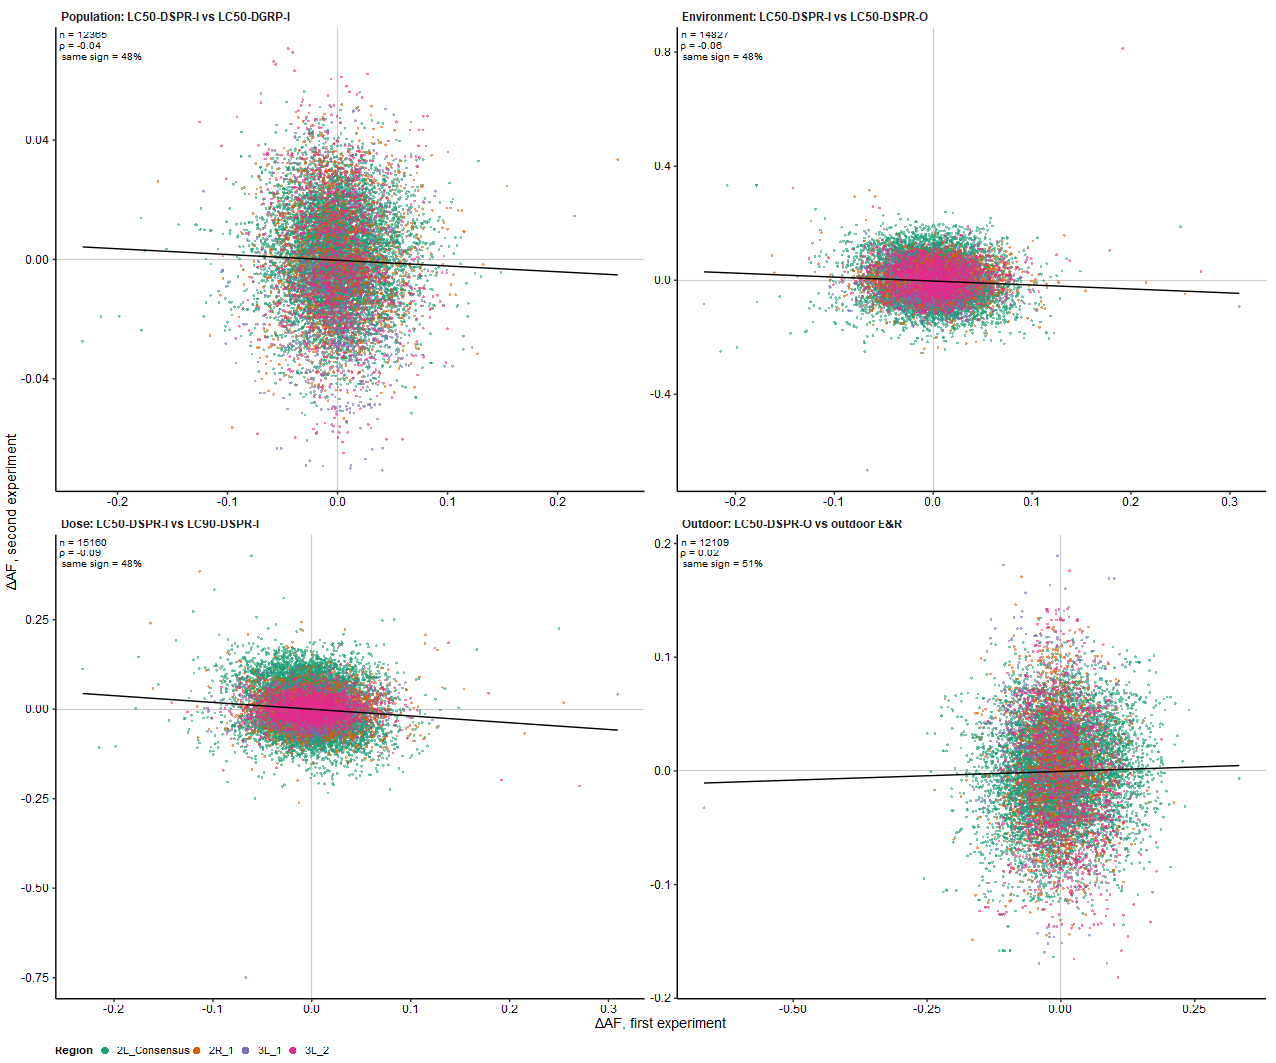

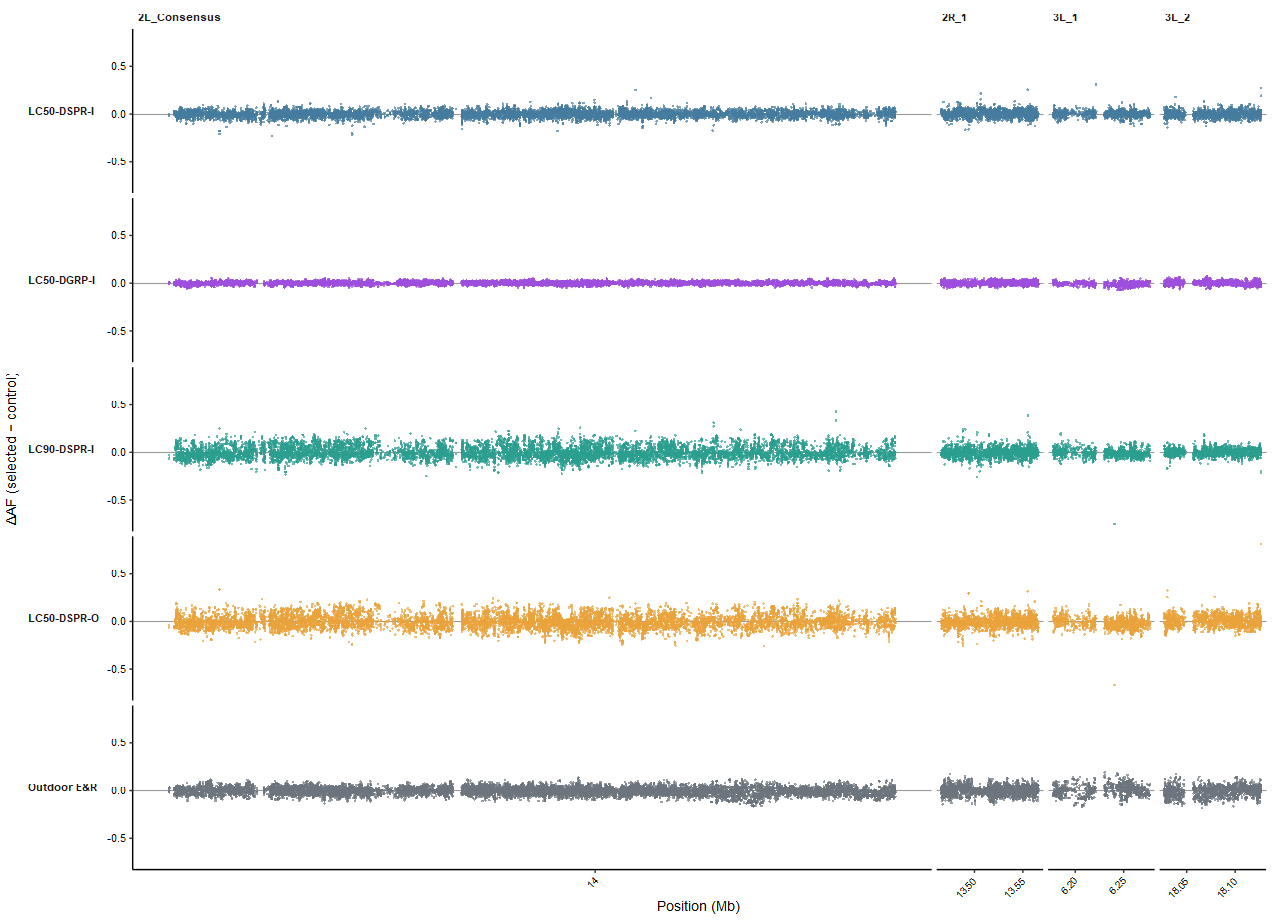

In [26]:
CONTRASTS <- tribble(
  ~contrast,                                     ~a,            ~b,
  "Population: LC50-DSPR-I vs LC50-DGRP-I",      "z_dspr3",     "z_dgrp",
  "Environment: LC50-DSPR-I vs LC50-DSPR-O",     "z_dspr3",     "z_outspino3",
  "Dose: LC50-DSPR-I vs LC90-DSPR-I",            "z_dspr3",     "z_dspr4",
  "Outdoor: LC50-DSPR-O vs outdoor E&R",         "z_outspino3", "outdoor")

## outdoor E - S dAF at the last timepoint, inside the triple regions
reg_dt  <- as.data.table(triple_regions)[, .(region, chr, fp_start, fp_end)]
out_tri <- reg_dt[out_snp, on = .(chr = CHROM, fp_start <= POS, fp_end > POS), nomatch = NULL,
                  .(region, chr = i.CHROM, POS = i.POS, dAF = i.delta, FDR = NA_real_)]
out_tri[, `:=`(panel = "Outdoor E&R", REF = NA_character_, ALT = NA_character_)]
site_tab <- function(id) {
  if (id == "outdoor") return(out_tri)
  peak_snps[zcol == id, .(region, chr, POS, REF, ALT, dAF, FDR, panel)]
}

## merge on position, then align alleles: swapped REF/ALT -> flip dAF_b, different alleles -> drop
pairs <- bind_rows(lapply(seq_len(nrow(CONTRASTS)), function(i) {
  A <- site_tab(CONTRASTS$a[i]); B <- site_tab(CONTRASTS$b[i])
  if (!nrow(A) || !nrow(B)) return(NULL)
  merge(A[, .(region, chr, POS, REF_a = REF, ALT_a = ALT, dAF_a = dAF, panel_a = panel)],
        B[, .(chr, POS, REF_b = REF, ALT_b = ALT, dAF_b = dAF, panel_b = panel)], by = c("chr", "POS")) %>%
    as_tibble() %>%
    mutate(allele = case_when(is.na(REF_a) | is.na(REF_b) | REF_a == "" | REF_b == "" ~ "unchecked",
                              REF_a == REF_b & ALT_a == ALT_b      ~ "same",
                              REF_a == ALT_b & ALT_a == REF_b      ~ "swapped",
                              TRUE                                 ~ "mismatch"),
           dAF_b = ifelse(allele == "swapped", -dAF_b, dAF_b),
           contrast = CONTRASTS$contrast[i])
})) %>% mutate(contrast = factor(contrast, levels = CONTRASTS$contrast))
cat("allele alignment per contrast:\n"); print(count(pairs, contrast, allele) %>% pivot_wider(names_from = allele, values_from = n))
pairs <- filter(pairs, allele != "mismatch")
write.csv(pairs, file.path(DATA, "matched_contrast_dAF_sites.csv"), row.names = FALSE)

pair_stats <- function(df) df %>% summarise(n_shared = n(),
  rho = if (n() > 2) suppressWarnings(cor(dAF_a, dAF_b, method = "spearman")) else NA_real_,
  sign_agree = mean(sign(dAF_a) == sign(dAF_b)), .groups = "drop")
stats_tab <- bind_rows(pairs %>% group_by(contrast) %>% pair_stats() %>% mutate(region = "ALL"),
                       pairs %>% group_by(contrast, region) %>% pair_stats()) %>%
  relocate(contrast, region) %>% arrange(contrast, region != "ALL", region)
write.csv(stats_tab, file.path(DATA, "matched_contrast_dAF_stats.csv"), row.names = FALSE)
print(stats_tab, n = Inf)

## ---- Supplement: matched-contrast scatter ------------------------------------
lab_df <- stats_tab %>% filter(region == "ALL") %>%
  mutate(label = sprintf("n = %d\n\u03C1 = %.2f\nsame sign = %.0f%%", n_shared, rho, 100 * sign_agree))
g_pairs <- ggplot(pairs, aes(dAF_a, dAF_b)) +
  geom_hline(yintercept = 0, colour = "grey80", linewidth = 0.25) +
  geom_vline(xintercept = 0, colour = "grey80", linewidth = 0.25) +
  geom_point(aes(colour = region), size = 0.5, alpha = 0.6, stroke = 0) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = "black", linewidth = 0.3) +
  geom_text(data = lab_df, aes(x = -Inf, y = Inf, label = label), hjust = -0.08, vjust = 1.15, size = 2.1,
            lineheight = 0.9, inherit.aes = FALSE) +
  facet_wrap(~ contrast, scales = "free", ncol = 2) +
  scale_colour_brewer(palette = "Dark2", name = "Region") +
  labs(x = "\u0394AF, first experiment", y = "\u0394AF, second experiment") +
  guides(colour = guide_legend(nrow = 1, override.aes = list(size = 1.8, alpha = 1))) +
  theme_pub() + theme(legend.position = "bottom", legend.justification = "left")
save_pub(g_pairs, "matched_contrast_dAF_scatter", h = mm(150))
print(g_pairs)

## ---- Supplement: per-SNP dAF along each triple region, every experiment + field ----
trk <- bind_rows(as_tibble(peak_snps[, .(region, POS, dAF, panel)]),
                 as_tibble(out_tri[, .(region, POS, dAF, panel)])) %>%
  mutate(panel  = factor(panel, levels = c(PANELS[SNP_PANELS], "Outdoor E&R")),
         region = factor(region, levels = reg_levels$region,
                         labels = reg_levels$region))

g_trk <- ggplot(trk, aes(POS / 1e6, dAF, colour = panel)) +
  geom_hline(yintercept = 0, linewidth = 0.25, colour = "grey60") +
  geom_point(size = 0.45, stroke = 0, alpha = 0.7) +
  scale_colour_manual(values = PANEL_COL, guide = "none") +
  facet_grid(panel ~ region, scales = "free_x", space = "free_x", switch = "y") +
  scale_x_continuous(breaks = scales::breaks_pretty(2)) +
  labs(x = "Position (Mb)", y = "\u0394AF (selected \u2212 control)") +
  theme_pub() +
  theme(strip.placement = "outside", strip.text.y.left = element_text(angle = 0, size = 6.5, face = "bold"),
        strip.text.x = element_text(size = 6, face = "bold"), axis.text.x = element_text(size = 5.5, angle = 45, hjust = 1),
        axis.text.y = element_text(size = 6), panel.spacing = unit(3, "pt"))
save_pub(g_trk, "dAF_all_panels_triple_regions", h = mm(130))
g_trk

## 5. Outdoor ΔAF in triple regions vs genome background

Per triple region: mean signed ΔAF (two-sided) and mean |ΔAF| (one-sided) of every outdoor SNP in the region, ranked against `N_BG` random intervals **of the same length** placed anywhere on the main arms outside all triple regions (each with ≥ `MIN_SNP_WIN` SNPs). Matching the length keeps the null's variance comparable for the 100 kb single-peak regions and the ~750 kb Consensus region. Violins pool `N_NULL_WINDOWS` random 50 kb windows outside the regions (display only).

Data: `outdoor_dAF_triple_regions_empirical.csv`. Figure: `outdoor_dAF_triple_regions_violins.png`.

# A tibble: 4 × 14
  region       lab                              chr   fp_start   fp_end span_kb
  <chr>        <chr>                            <chr>    <dbl>    <dbl>   <int>
1 2L_Consensus 2L_Consensus (2L 13.56-14.31 Mb) 2L    13560000 14310000     750
2 2R_1         2R_1 (2R 13.47-13.57 Mb)         2R    13466000 13566000     100
3 3L_1         3L_1 (3L 6.18-6.28 Mb)           3L     6177000  6277000     100
4 3L_2         3L_2 (3L 18.03-18.13 Mb)         3L    18027000 18127000     100
      n        m   mabs p_emp_mean p_emp_absdAF bg_mean_absdAF p_BH_mean
  <int>    <dbl>  <dbl>      <dbl>        <dbl>          <dbl>     <dbl>
1 15138 -0.00486 0.0308      0.537       0.667          0.0335     0.537
2  2825  0.00181 0.0351      0.507       0.389          0.0333     0.537
3  1412  0.00666 0.0438      0.184       0.0555         0.0335     0.537
4  2045 -0.00841 0.0431      0.315       0.0650         0.0333     0.537
  p_BH_absdAF
        <dbl>
1       0.667
2       0.519
3      

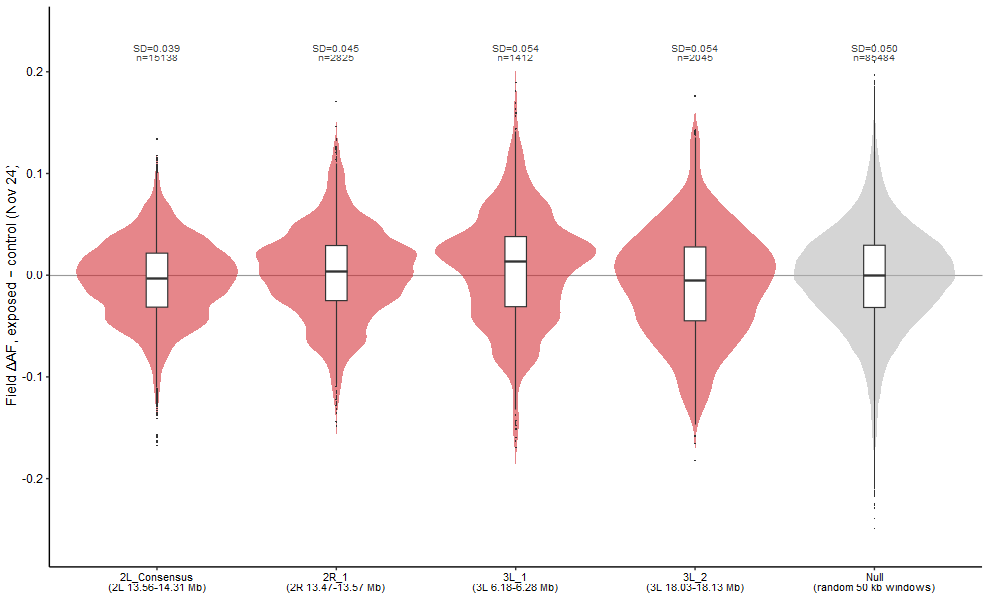

In [27]:
## ---- SNPs inside each region --------------------------------------------------
reg_dt  <- as.data.table(triple_regions)[, .(region, chr, fp_start, fp_end)]
excl_dt <- as.data.table(regions_all)[, .(chr, fp_start, fp_end)]                  # exclude every region from the null
daf_reg <- reg_dt[out_snp, on = .(chr = CHROM, fp_start <= POS, fp_end > POS), nomatch = NULL, .(region, delta = i.delta)]
reg_sum <- daf_reg[, .(n = .N, m = mean(delta), mabs = mean(abs(delta))), by = region]

## ---- same-length background intervals (prefix sums: O(log n) per interval) ----------
arm_tab <- lapply(split(out_snp[CHROM %in% CHROMS][order(CHROM, POS)], by = "CHROM"), function(a)
  list(P = a$POS, C1 = c(0, cumsum(a$delta)), C2 = c(0, cumsum(abs(a$delta)))))
iv_stats <- function(a, s, e) {
  lo <- findInterval(s - 1, a$P); hi <- findInterval(e - 1, a$P); n <- hi - lo
  data.table(n = n, m = (a$C1[hi + 1] - a$C1[lo + 1]) / n, mabs = (a$C2[hi + 1] - a$C2[lo + 1]) / n)
}
bg_draw <- function(L, n_draw) {
  span <- vapply(arm_tab, function(a) max(0, diff(range(a$P)) - L), numeric(1))
  out <- list(); got <- 0L
  while (got < n_draw) {
    k  <- 2L * (n_draw - got)
    ch <- sample(names(arm_tab), k, replace = TRUE, prob = span)
    res <- rbindlist(lapply(split(seq_len(k), ch), function(ix) {
      arm <- ch[ix[1]]; a <- arm_tab[[arm]]
      s <- runif(length(ix), min(a$P), max(a$P) - L); e <- s + L
      ex <- excl_dt[chr == arm]
      bad <- if (nrow(ex)) vapply(seq_along(s), function(j) any(s[j] < ex$fp_end & e[j] > ex$fp_start), logical(1)) else FALSE
      iv_stats(a, s, e)[!bad]
    }))
    res <- res[n >= MIN_SNP_WIN]; out[[length(out) + 1L]] <- res; got <- got + nrow(res)
  }
  rbindlist(out)[seq_len(n_draw)]
}

emp <- reg_levels %>% dplyr::select(region, lab, chr, fp_start, fp_end, span_kb) %>%
  left_join(as_tibble(reg_sum), by = "region") %>%
  rowwise() %>%
  mutate(bg = list(bg_draw(fp_end - fp_start, N_BG)),
         p_emp_mean   = (1 + sum(abs(bg$m - mean(bg$m)) >= abs(m - mean(bg$m)))) / (N_BG + 1),
         p_emp_absdAF = (1 + sum(bg$mabs >= mabs)) / (N_BG + 1),
         bg_mean_absdAF = mean(bg$mabs)) %>%
  ungroup() %>% dplyr::select(-bg) %>%
  mutate(p_BH_mean = p.adjust(p_emp_mean, "BH"), p_BH_absdAF = p.adjust(p_emp_absdAF, "BH"))
print(as_tibble(emp), width = Inf)
write.csv(emp, file.path(DATA, "outdoor_dAF_triple_regions_empirical.csv"), row.names = FALSE)

## ---- violins: region SNPs vs SNPs of random 50 kb windows outside every region (display) ----
grid_dt <- as.data.table(conc50)[, .(chr, win_start, win_end)][, window_id := sprintf("%s:%d", chr, as.integer(win_start))]
grid_dt <- grid_dt[!excl_dt, on = .(chr, win_start < fp_end, win_end > fp_start)]
daf_bg  <- grid_dt[out_snp, on = .(chr = CHROM, win_start <= POS, win_end > POS), nomatch = NULL, .(window_id, delta = i.delta)]
bg_ids  <- daf_bg[, .N, by = window_id][N >= MIN_SNP_WIN, window_id]
null_ids <- sample(bg_ids, min(N_NULL_WINDOWS, length(bg_ids)))
NULL_LAB <- "Null\n(random 50 kb windows)"
viol_df <- bind_rows(
  daf_reg %>% as_tibble() %>% left_join(dplyr::select(reg_levels, region, lab), by = "region") %>% transmute(region = lab, delta),
  daf_bg[window_id %in% null_ids] %>% as_tibble() %>% transmute(region = NULL_LAB, delta)) %>%
  mutate(region = factor(region, levels = c(reg_levels$lab, NULL_LAB)))
lab_stats <- viol_df %>% group_by(region) %>% summarise(sd = sd(delta), n = n(), .groups = "drop") %>%
  mutate(lab = sprintf("SD=%.3f\nn=%d", sd, n))

TPT_DATE <- c(tpt1 = "Aug 24", tpt2 = "Sep 30", tpt3 = "Oct 27", tpt4 = "Nov 24")
wrap_lab <- function(x) ifelse(x == NULL_LAB, x, sub(" \\(", "\n(", x))

viol <- ggplot(viol_df, aes(region, delta, fill = region == NULL_LAB)) +
  geom_hline(yintercept = 0, colour = "grey60", linewidth = 0.25) +
  geom_violin(scale = "width", colour = NA, alpha = 0.55, trim = FALSE) +
  geom_boxplot(width = 0.12, outlier.size = 0.2, outlier.stroke = 0, fill = "white", linewidth = 0.25) +
  geom_text(data = lab_stats, aes(region, y = max(viol_df$delta), label = lab), inherit.aes = FALSE,
            vjust = 1, size = 1.9, colour = "grey25", lineheight = 0.9) +
  scale_fill_manual(values = c(`FALSE` = SUP_RED, `TRUE` = "grey70"), guide = "none") +
  scale_x_discrete(labels = wrap_lab) +
  labs(x = NULL, y = sprintf("Field ΔAF, exposed − control (%s)",
                             TPT_DATE[[sub("^dAF_t", "tpt", DAF_LAST)]])) +
  theme_pub() + theme(axis.text.x = element_text(size = 6, lineheight = 0.9))
save_pub(viol, "outdoor_dAF_triple_regions_violins", w = mm(140), h = mm(85))
viol

## 6. Outdoor (primary, median |z|) × LC50-DSPR-O rank concordance

Each window's genome-wide percentile in the primary outdoor track and in LC50-DSPR-O. Colour = each track's own percentile tier; shape = joint tier (strictest level where both tracks qualify). 90 / 99 tiers are display only; the saved overlap set is the 95th-percentile rule (both tracks ≥ 95th), saved with each window's X-QTL scan footprint (`fp_start`, `fp_end` = scan position ± 50 kb) so notebook 04 takes genes from the footprint, not the 50 kb window.

Data: `outdoor_95th_overlap_windows.csv` (read by notebook 04). Figure: `outdoor_rankrank_overlap_manhattan.png`.

windows per joint tier:

none 90th 95th 99th 
1919   24    8    0 
joint 95th+ overlap windows: 8


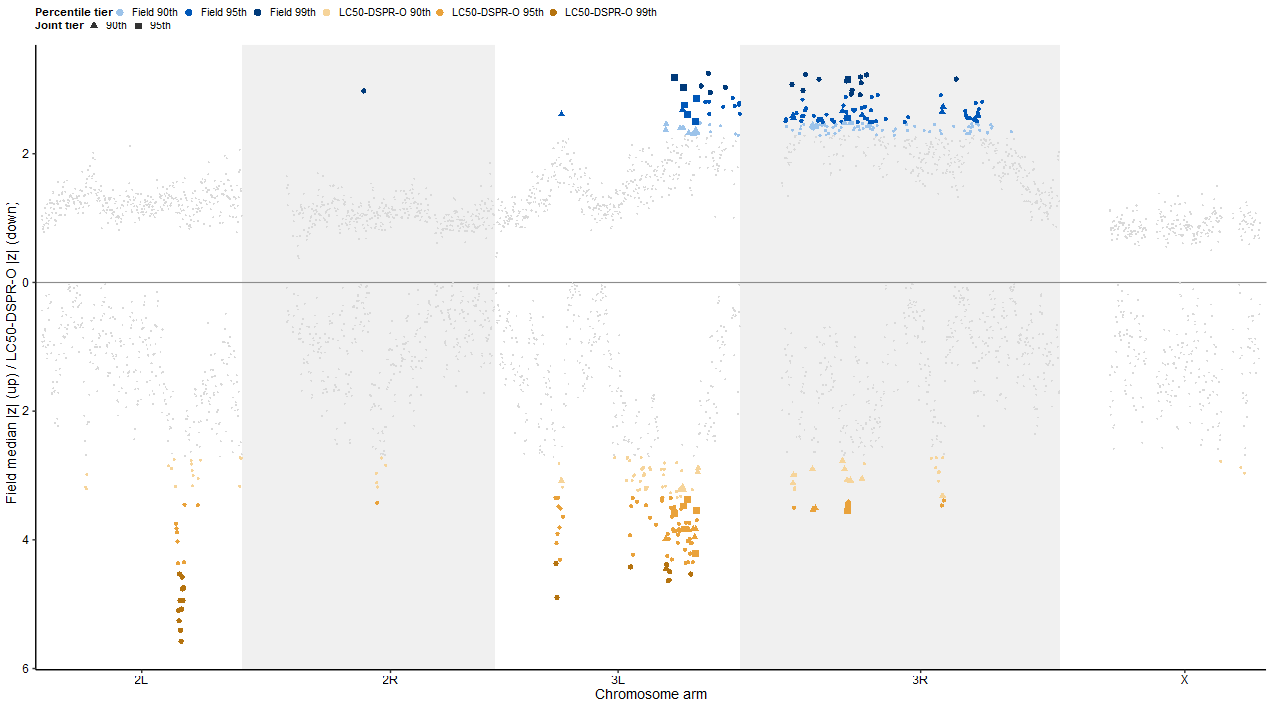

In [28]:
OCOL <- paste0("out_", PRIMARY, "_", OUT_STAT)
tier_of <- function(pr) case_when(pr >= 0.99 ~ "99th", pr >= Q_CUT ~ "95th", pr >= 0.90 ~ "90th", TRUE ~ "none")
TLEV <- c("none", "90th", "95th", "99th")

rr <- conc50 %>% filter(chr %in% CHROMS) %>%
  mutate(chr = factor(chr, levels = CHROMS),
         pr_out = cume_dist(.data[[OCOL]]), pr_spino = cume_dist(z_outspino3),
         tier_out = factor(tier_of(pr_out), levels = TLEV), tier_spino = factor(tier_of(pr_spino), levels = TLEV),
         tier = factor(tier_of(pmin(pr_out, pr_spino)), levels = TLEV))
cat("windows per joint tier:\n"); print(table(rr$tier))

off  <- rr %>% group_by(chr) %>% summarise(len = max(win_end), .groups = "drop") %>% arrange(chr) %>%
  mutate(offset = lag(cumsum(len), default = 0))
man  <- rr %>% left_join(off, by = "chr") %>% mutate(cum = win_start + offset)
ax   <- man %>% group_by(chr) %>% summarise(center = mean(range(cum)), .groups = "drop")
band <- off %>% mutate(xmin = offset, xmax = offset + len) %>% filter(row_number() %% 2 == 0)

pal <- c("none" = "grey85",
         "Field 90th" = "#9CC3EA", "Field 95th" = SUP_BLUE, "Field 99th" = "#003A7A",
         "LC50-DSPR-O 90th" = "#F6D49A", "LC50-DSPR-O 95th" = "#E9A23B", "LC50-DSPR-O 99th" = "#B5730F")
shape_vals <- c(none = 16, "90th" = 17, "95th" = 15, "99th" = 18)
tier_size  <- c(none = 0.3, "90th" = 0.6, "95th" = 0.9, "99th" = 1.2)
joint_size <- c("90th" = 1.5, "95th" = 1.9, "99th" = 2.4)

plot_df <- bind_rows(
  man %>% transmute(cum, y =  .data[[OCOL]],   dataset = "Field",       ctier = tier_out,   conc = tier),
  man %>% transmute(cum, y = -z_outspino3,     dataset = "LC50-DSPR-O", ctier = tier_spino, conc = tier)) %>%
  mutate(key = factor(ifelse(ctier == "none", "none", paste(dataset, ctier)), levels = names(pal)),
         concordant = conc != "none",
         sz  = ifelse(concordant, joint_size[as.character(conc)], tier_size[as.character(ctier)]),
         ord = ifelse(concordant, 100L + as.integer(conc), as.integer(ctier))) %>%
  arrange(ord)

## ---- Supplement: field x LC50-DSPR-O rank concordance (Supplemental Figure 6) ----
fig_rr <- ggplot(plot_df, aes(cum, y, colour = key, shape = conc, size = sz)) +
  geom_rect(data = band, aes(xmin = xmin, xmax = xmax, ymin = -Inf, ymax = Inf), fill = "grey94", inherit.aes = FALSE) +
  geom_hline(yintercept = 0, colour = "grey55", linewidth = 0.25) +
  geom_point(stroke = 0) +
  scale_colour_manual(values = pal, breaks = names(pal)[-1], name = "Percentile tier") +
  scale_shape_manual(values = shape_vals, breaks = c("90th", "95th", "99th"), name = "Joint tier") +
  scale_size_identity() +
  scale_x_continuous(breaks = ax$center, labels = ax$chr, expand = expansion(mult = 0.005)) +
  scale_y_continuous(labels = function(b) abs(b)) +
  labs(x = "Chromosome arm", y = sprintf("Field %s |z| (up) / LC50-DSPR-O |z| (down)", OUT_STAT)) +
  guides(colour = guide_legend(nrow = 1, order = 1, override.aes = list(size = 1.8, shape = 16)),
         shape  = guide_legend(nrow = 1, order = 2, override.aes = list(size = 1.8, colour = "grey20"))) +
  theme_pub() + theme(legend.position = "top", legend.justification = "left", legend.box = "vertical",
                      legend.box.just = "left", legend.spacing.y = unit(1, "pt"))
save_pub(fig_rr, "outdoor_rankrank_overlap_manhattan", h = mm(100))

windows_95 <- man %>% filter(pr_out >= Q_CUT, pr_spino >= Q_CUT) %>%
  transmute(chr = as.character(chr), win_start, win_end,
            fp_start = win_start + POS_OFFSET - SCAN_HALF, fp_end = win_end - POS_OFFSET + SCAN_HALF,
            out_score = .data[[OCOL]], z_outspino3, pr_out, pr_spino, tier) %>%
  arrange(desc(pr_out + pr_spino))
names(windows_95)[names(windows_95) == "out_score"] <- OCOL
write.csv(windows_95, file.path(DATA, "outdoor_95th_overlap_windows.csv"), row.names = FALSE)
cat(sprintf("joint 95th+ overlap windows: %d\n", nrow(windows_95)))
fig_rr

## 7. Four-way concordance classes and their genes

Each 50 kb window gets an exact signature: which of the four xQTL panels are ≥ their own 95th percentile (15 classes). Windows of each class (tier ≥ `MIN_CLASS_TIER`) are merged into contiguous peaks and annotated with genes (cached Ensembl coords from 02). Peak genes use the scan footprint (first scan position − 50 kb to last + 50 kb), as for the triple regions; window genes use the raw 50 kb windows. The window-level class Manhattan itself is drawn in notebook 02 (`concordance_class_manhattan.png`).

Data (in `concordance_classes/`): `all_windows_annotated.csv`, `overlap_summary_counts.csv`, `tier<k>__<class>_windows.csv`, `tier<k>__<class>_peak_genes.csv`, `…_window_genes.csv`, `ALL_classes_peak_genes.csv`, `ALL_classes_window_genes.csv`, `genes_by_class_counts.csv`. Figures: `tier<k>__<class>_peak_genes_table.png`, `genes_by_class_histogram.png`.

# A tibble: 15 × 3
   class                                                  tier n_windows
   <chr>                                                 <int>     <int>
 1 LC50-DGRP-I                                               1        78
 2 LC50-DSPR-I                                               1        77
 3 LC90-DSPR-I                                               1        70
 4 LC50-DSPR-O                                               1        61
 5 LC50-DGRP-I & LC50-DSPR-I                                 2         6
 6 LC50-DGRP-I & LC90-DSPR-I                                 2         1
 7 LC50-DGRP-I & LC50-DSPR-O                                 2         9
 8 LC50-DSPR-I & LC90-DSPR-I                                 2         6
 9 LC50-DSPR-I & LC50-DSPR-O                                 2         4
10 LC90-DSPR-I & LC50-DSPR-O                                 2        14
11 LC50-DGRP-I & LC50-DSPR-I & LC90-DSPR-I                   3         0
12 LC50-DGRP-I & LC50-DSPR-I & L

LC50-DGRP-I & LC50-DSPR-I: 6 windows, 6 peaks, 119 genes

LC50-DGRP-I & LC90-DSPR-I: 1 windows, 1 peaks, 14 genes



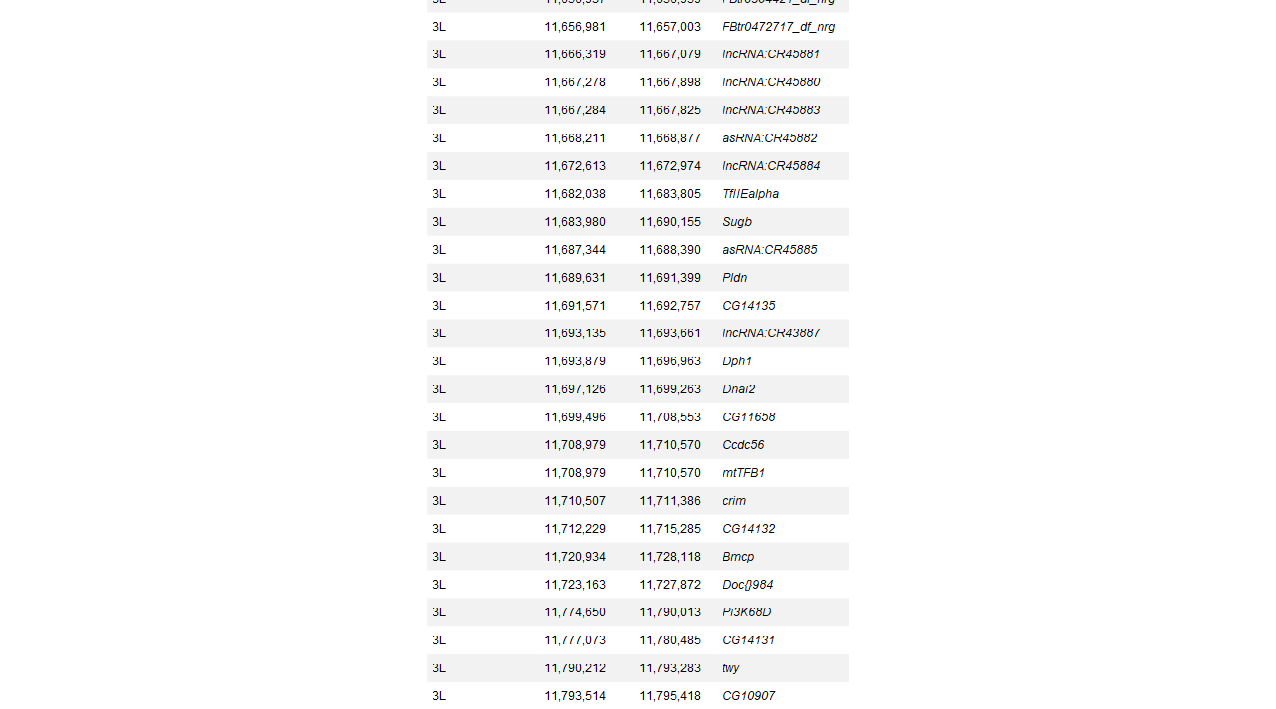

LC50-DGRP-I & LC50-DSPR-O: 9 windows, 9 peaks, 151 genes



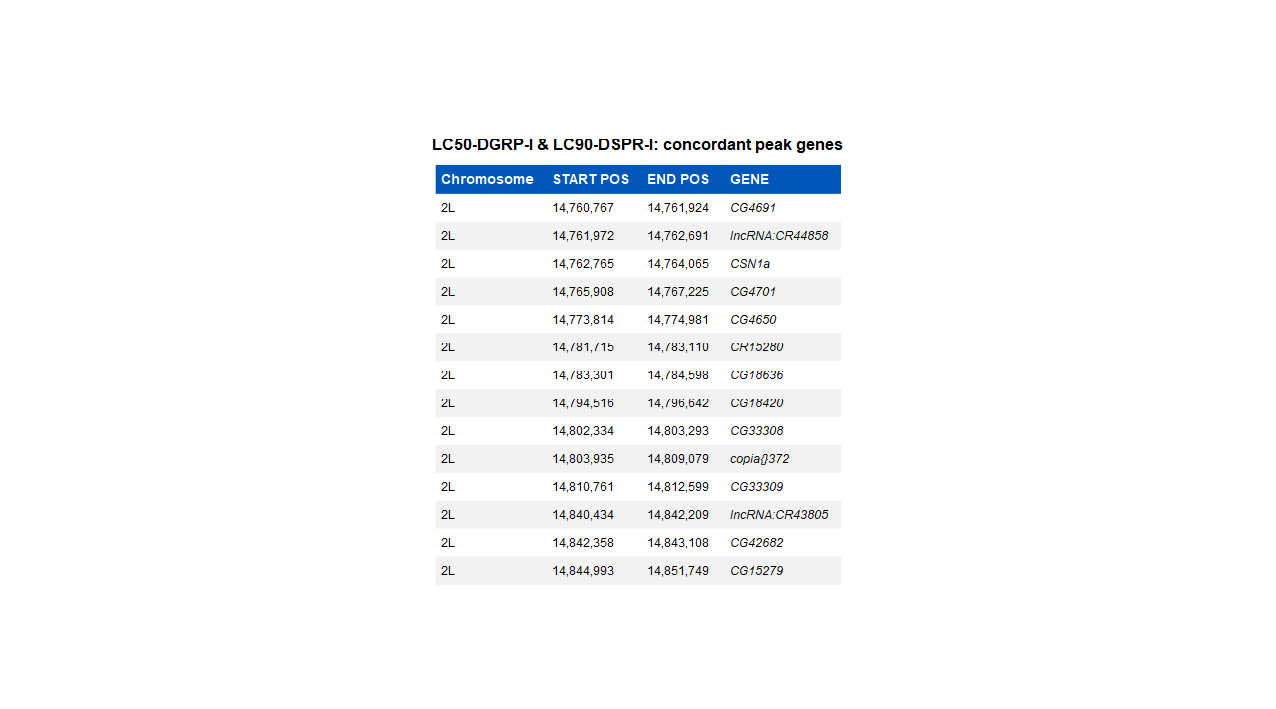

LC50-DSPR-I & LC90-DSPR-I: 6 windows, 4 peaks, 86 genes



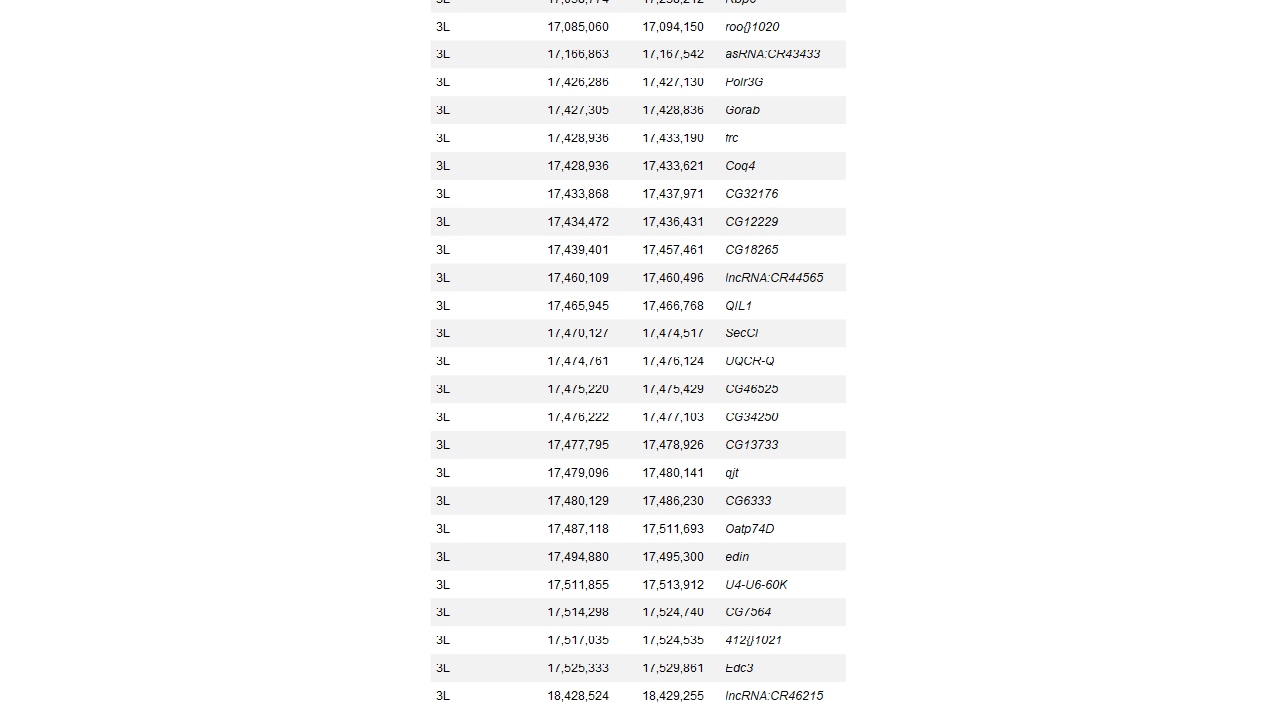

LC50-DSPR-I & LC50-DSPR-O: 4 windows, 3 peaks, 54 genes



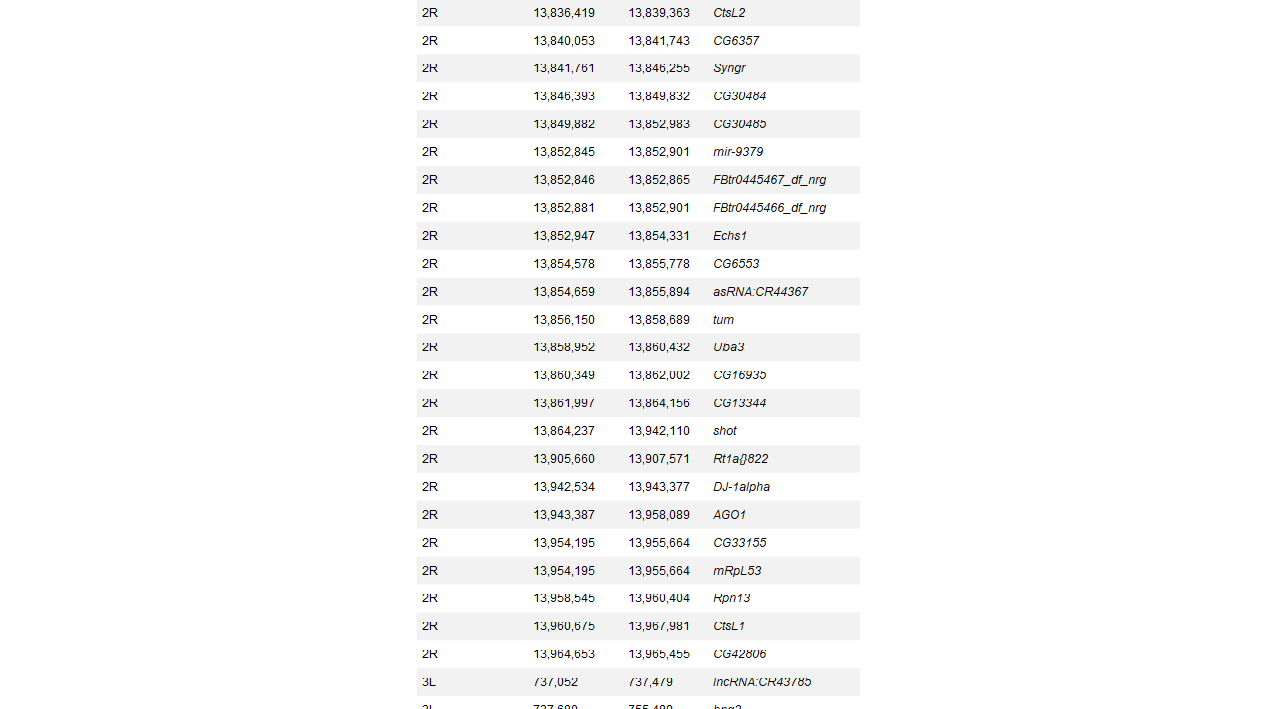

LC90-DSPR-I & LC50-DSPR-O: 14 windows, 6 peaks, 185 genes



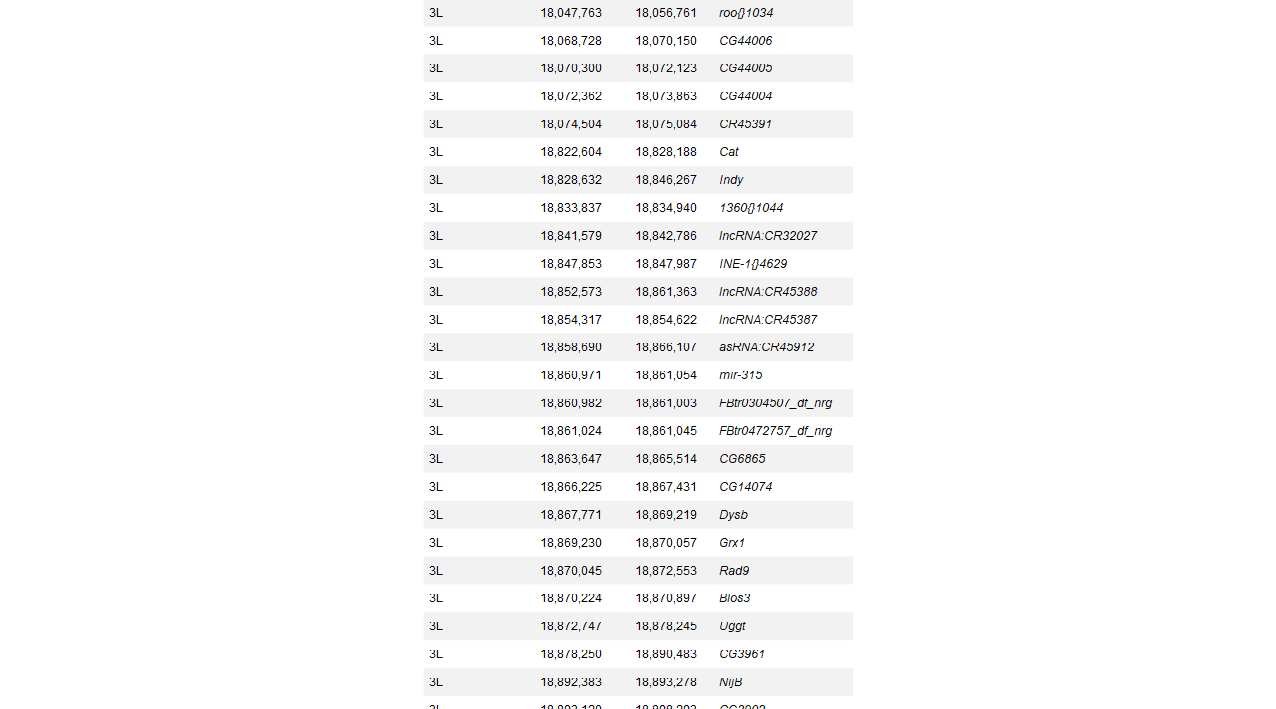

LC50-DGRP-I & LC50-DSPR-I & LC90-DSPR-I: no windows

LC50-DGRP-I & LC50-DSPR-I & LC50-DSPR-O: 1 windows, 1 peaks, 22 genes



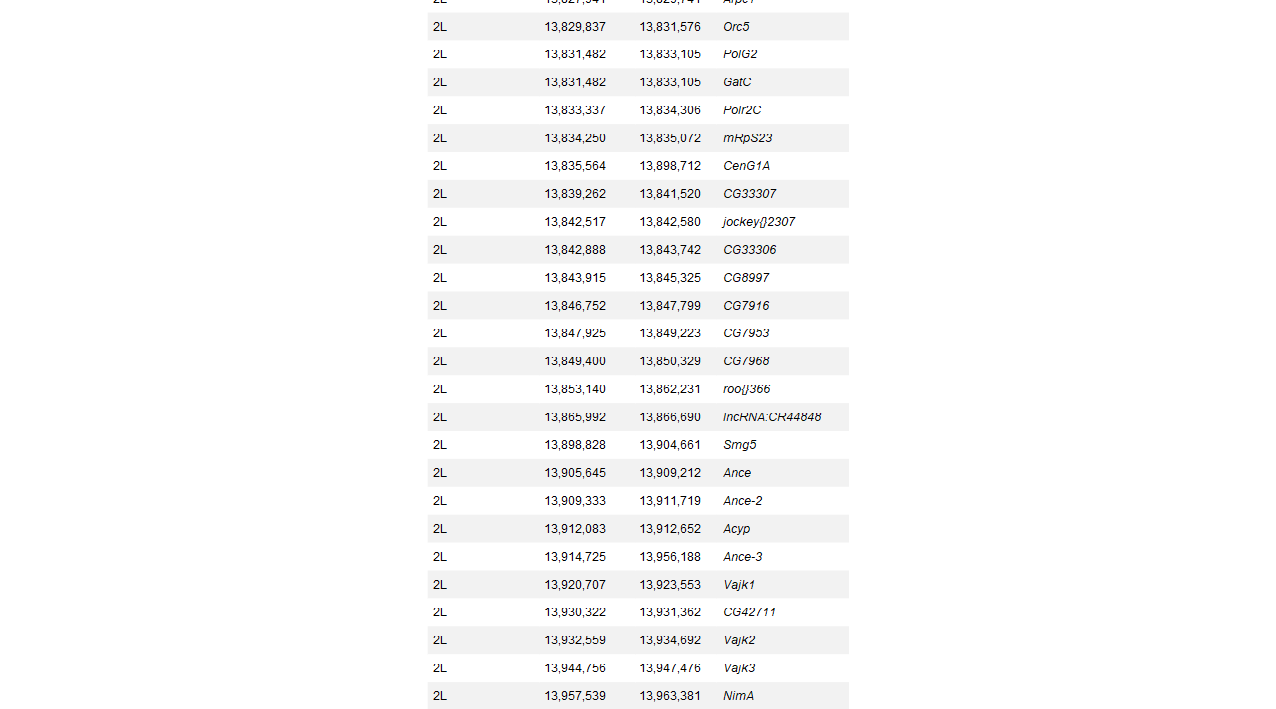

LC50-DGRP-I & LC90-DSPR-I & LC50-DSPR-O: 3 windows, 3 peaks, 62 genes



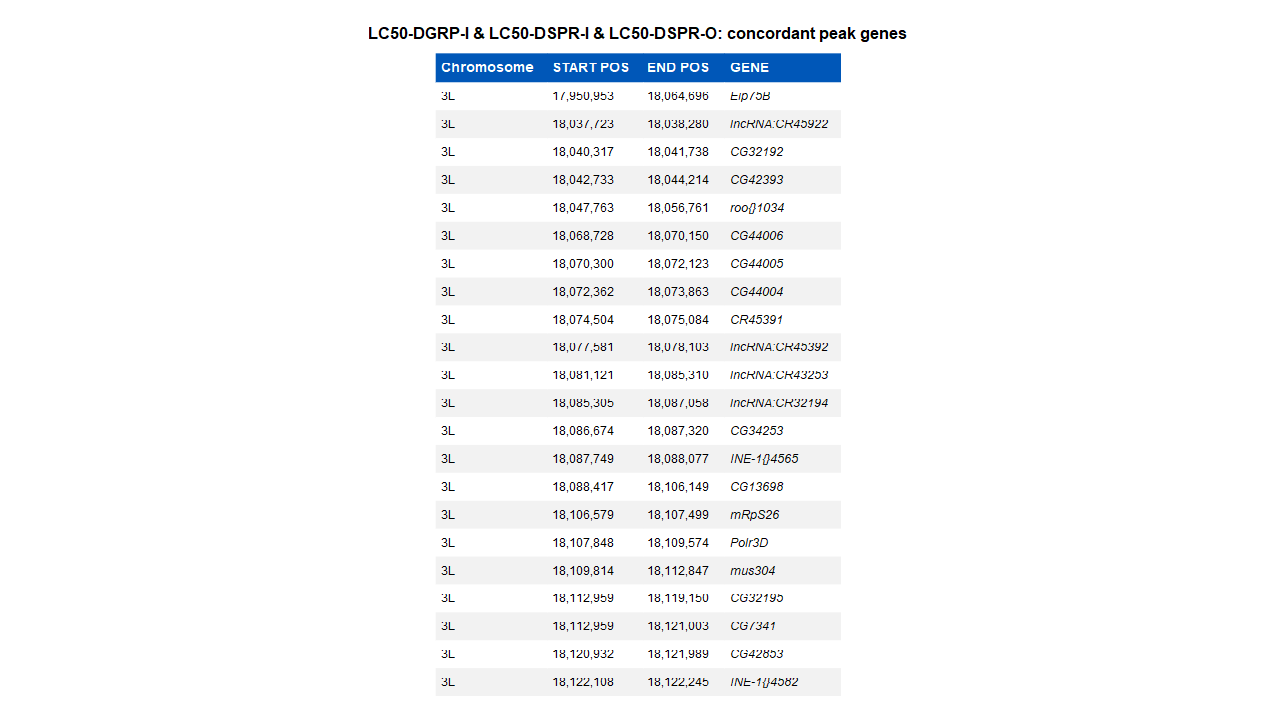

LC50-DSPR-I & LC90-DSPR-I & LC50-DSPR-O: 4 windows, 3 peaks, 62 genes



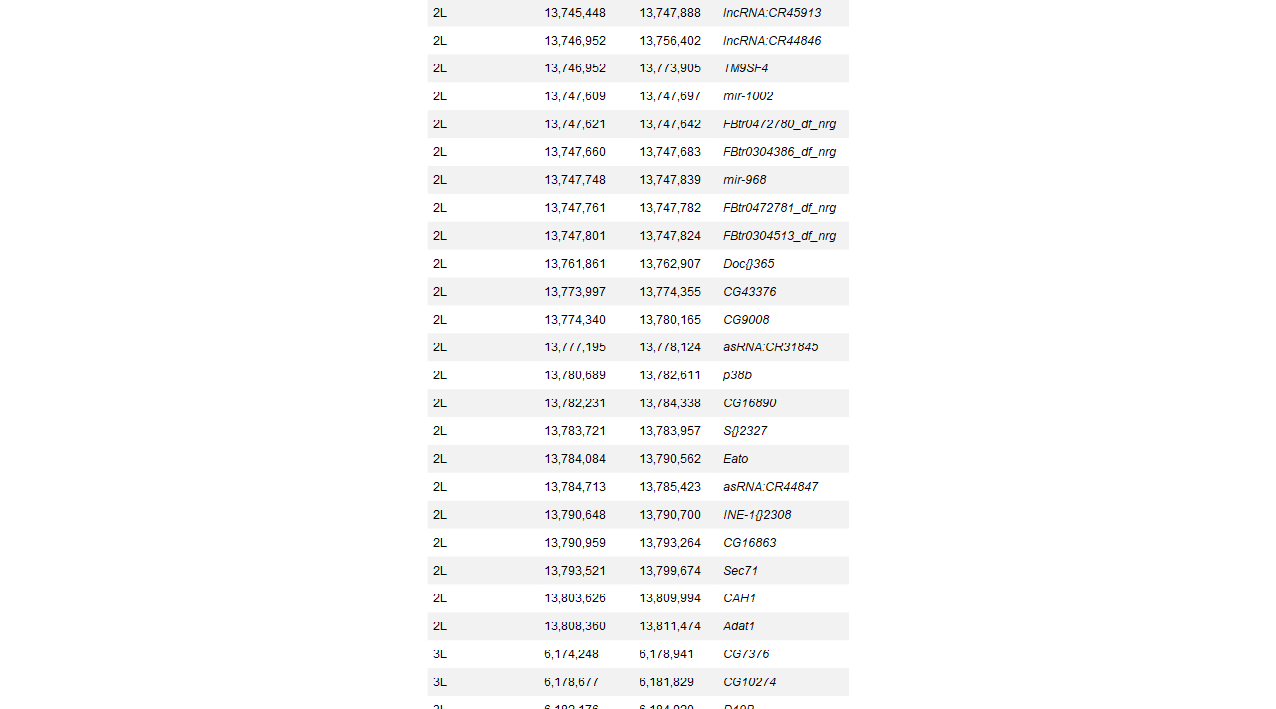

LC50-DGRP-I & LC50-DSPR-I & LC90-DSPR-I & LC50-DSPR-O: no windows



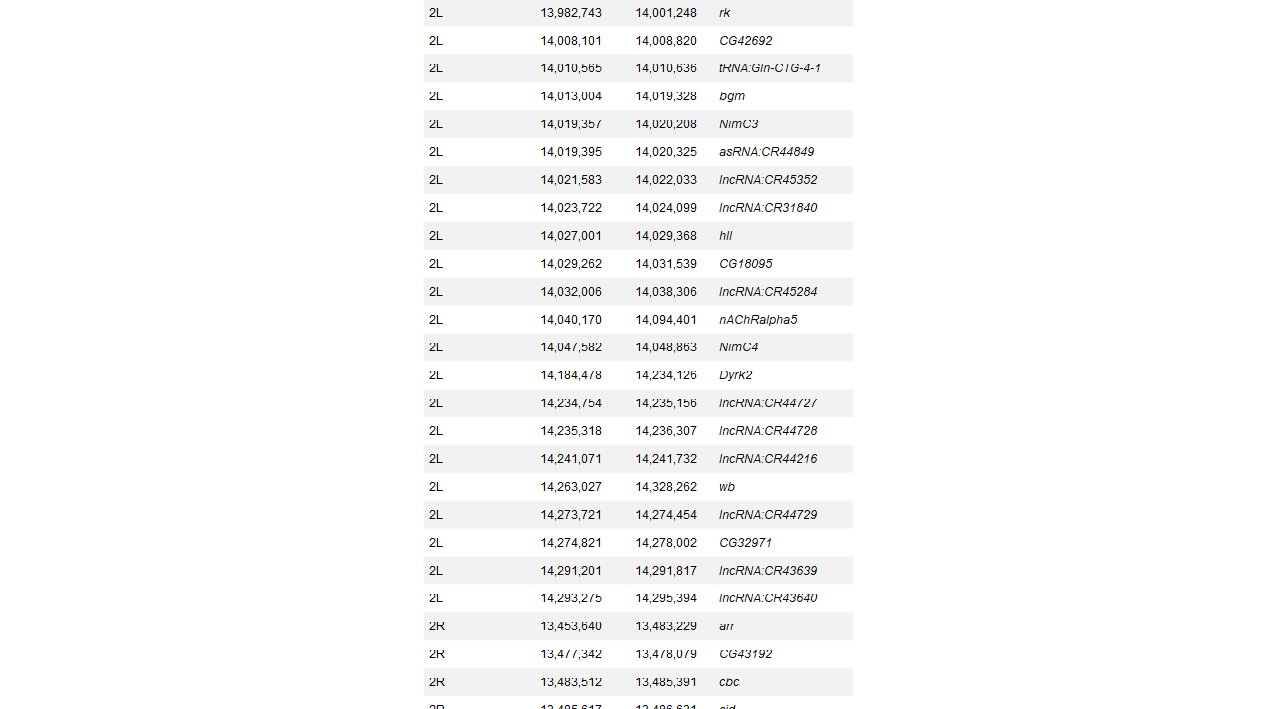

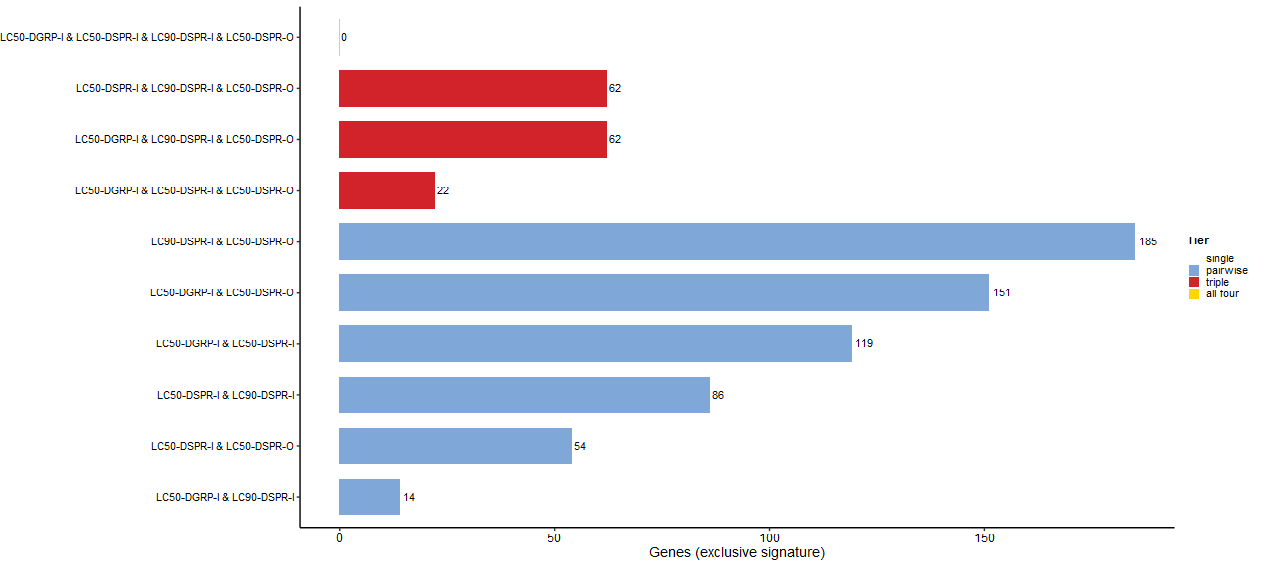

In [29]:
MIN_CLASS_TIER <- 2
MEMBERSHIP     <- "exclusive"   # "exclusive": window belongs to exactly one class; "inclusive": all members hit
src  <- names(PANELS)
safe <- function(x) gsub("[^A-Za-z0-9]+", "_", x)
CUTS <- sapply(src, function(cc) qcut(conc50[[cc]]))

combos    <- unlist(lapply(seq_along(src), function(k) combn(src, k, simplify = FALSE)), recursive = FALSE)
combo_lab <- vapply(combos, function(cc) paste(PANELS[cc], collapse = " & "), "")
combo_n   <- lengths(combos)

Bm <- vapply(src, function(cc) conc50[[cc]] > CUTS[[cc]], logical(nrow(conc50)))
ann <- conc50 %>%
  mutate(ntier = as.integer(rowSums(Bm)),
         sig = ifelse(ntier == 0, "None", apply(Bm, 1, function(r) paste(PANELS[src][r], collapse = " & ")))) %>%
  bind_cols(setNames(as.data.frame(Bm), paste0("hit_", PANELS[src])))
write.csv(ann, file.path(CLS_DIR, "all_windows_annotated.csv"), row.names = FALSE)
summary_tbl <- tibble(class = combo_lab, tier = combo_n,
                      n_windows = as.integer(table(factor(ann$sig, levels = combo_lab))))
write.csv(summary_tbl, file.path(CLS_DIR, "overlap_summary_counts.csv"), row.names = FALSE)
print(summary_tbl, n = Inf)

gene_gr <- GRanges(gene_coords$gene_chr, IRanges(gene_coords$gene_start, gene_coords$gene_end))
overlap_genes <- function(iv, start_col, end_col, id_cols) {
  h <- findOverlaps(GRanges(iv$chr, IRanges(iv[[start_col]], iv[[end_col]] - 1)), gene_gr)
  bind_cols(iv[queryHits(h), id_cols, drop = FALSE], gene_coords[subjectHits(h), ])
}

all_peak_genes <- list(); all_window_genes <- list()
for (i in which(combo_n >= MIN_CLASS_TIER)) {
  cc <- combos[[i]]; lb <- combo_lab[i]; tag <- sprintf("tier%d__%s", combo_n[i], safe(lb))
  w <- if (MEMBERSHIP == "exclusive") filter(ann, sig == lb) else ann[rowSums(Bm[, cc, drop = FALSE]) == length(cc), ]
  if (!nrow(w)) { message(lb, ": no windows"); next }
  memz <- as.matrix(w[, cc, drop = FALSE])
  w <- w %>% mutate(win_min_z = apply(memz, 1, min), win_max_z = apply(memz, 1, max)) %>%
    arrange(match(chr, CHROMS), win_start) %>% group_by(chr) %>%
    mutate(peak = sprintf("%s_%s_%d", safe(lb), chr, cumsum(is.na(lag(win_end)) | win_start != lag(win_end)))) %>%
    ungroup()
  write.csv(w, file.path(CLS_DIR, paste0(tag, "_windows.csv")), row.names = FALSE)
  pk <- w %>% group_by(peak, chr) %>%
    summarise(start = min(win_start) + POS_OFFSET - SCAN_HALF, end = max(win_end) - POS_OFFSET + SCAN_HALF,   # scan footprint
              n_win = n(), max_z = max(win_max_z), max_z_pos = win_start[which.max(win_max_z)], .groups = "drop") %>%
    mutate(span_kb = (end - start) / 1e3)
  pg <- overlap_genes(pk, "start", "end", c("peak", "chr", "start", "end", "span_kb", "n_win", "max_z", "max_z_pos")) %>%
    mutate(class = lb, tier = combo_n[i], .before = 1)
  wg <- overlap_genes(w, "win_start", "win_end", c("peak", "chr", "win_start", "win_end", "win_min_z", "win_max_z")) %>%
    mutate(class = lb, tier = combo_n[i], .before = 1)
  write.csv(pg, file.path(CLS_DIR, paste0(tag, "_peak_genes.csv")),   row.names = FALSE)
  write.csv(wg, file.path(CLS_DIR, paste0(tag, "_window_genes.csv")), row.names = FALSE)
  message(sprintf("%s: %d windows, %d peaks, %d genes", lb, nrow(w), nrow(pk), n_distinct(pg$ensembl_gene_id)))
  if (nrow(pg)) {
    disp <- pg %>% mutate(GENE = ifelse(is.na(gene_name) | gene_name == "", ensembl_gene_id, gene_name)) %>%
      distinct(ensembl_gene_id, .keep_all = TRUE) %>% arrange(match(gene_chr, CHROMS), gene_start) %>%
      transmute(Chromosome = gene_chr, `START POS` = comma(gene_start), `END POS` = comma(gene_end), GENE)
    save_table_png(disp, paste0(lb, ": concordant peak genes"), file.path(FIGS, paste0(tag, "_peak_genes_table.png")),
                   italic_col = "GENE")
  }
  all_peak_genes[[lb]] <- pg; all_window_genes[[lb]] <- wg
}
if (length(all_peak_genes)) {
  write.csv(bind_rows(all_peak_genes),   file.path(CLS_DIR, "ALL_classes_peak_genes.csv"),   row.names = FALSE)
  write.csv(bind_rows(all_window_genes), file.path(CLS_DIR, "ALL_classes_window_genes.csv"), row.names = FALSE)
}

## ---- genes per class ------------------------------------------------------
class_counts <- tibble(class = combo_lab, tier = combo_n,
                       n_genes = vapply(combo_lab, function(lb)
                         if (is.null(all_peak_genes[[lb]])) 0L else n_distinct(all_peak_genes[[lb]]$ensembl_gene_id),
                         integer(1))) %>%
  filter(tier >= MIN_CLASS_TIER)
write.csv(class_counts, file.path(CLS_DIR, "genes_by_class_counts.csv"), row.names = FALSE)
tier_tot <- class_counts %>% group_by(tier) %>% summarise(genes = sum(n_genes), .groups = "drop")
tot_of <- function(k) { v <- tier_tot$genes[tier_tot$tier == k]; if (length(v)) v else 0L }

plot_tbl <- class_counts %>% filter(n_genes > 0 | tier == length(src)) %>% arrange(tier, n_genes) %>%
  mutate(class = factor(class, levels = class), tier_f = factor(tier, levels = seq_along(src)))
g_cls <- ggplot(plot_tbl, aes(class, n_genes, fill = tier_f)) +
  geom_col(width = 0.7) + geom_text(aes(label = n_genes), hjust = -0.25, size = 2.2) +
  scale_fill_manual(values = c("1" = "grey75", "2" = "#7FA8D9", "3" = SUP_RED, "4" = "#ffd700"), name = "Tier",
                    labels = c("1" = "single", "2" = "pairwise", "3" = "triple", "4" = "all four"), drop = FALSE) +
  coord_flip(clip = "off") +
  labs(x = NULL, y = sprintf("Genes (%s signature)", MEMBERSHIP)) +
  theme_pub() + theme(axis.text.y = element_text(size = 6), plot.margin = margin(4, 20, 4, 4))
save_pub(g_cls, "genes_by_class_histogram", h = mm(80))
g_cls

## 8. Phenotypic selection intensity by X-QTL cross

Figure: `gauss_tail_combined.png`.

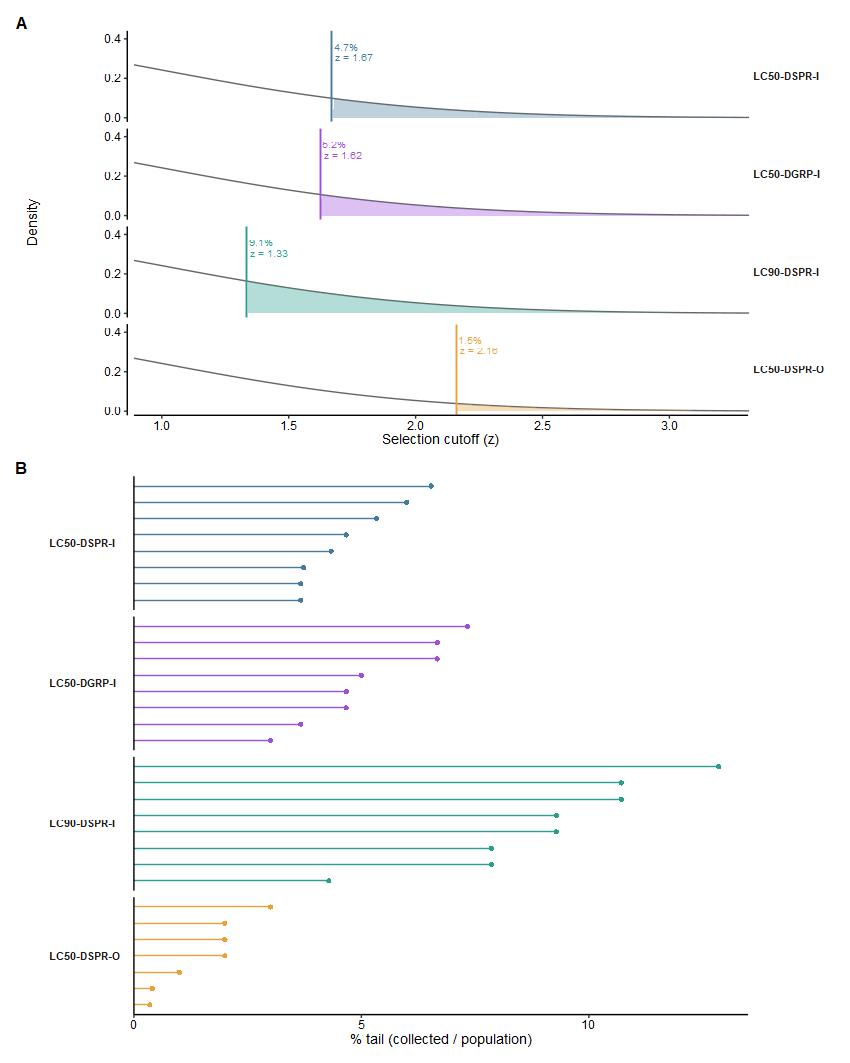

In [30]:
pheno    <- read.csv(file.path(IN_DIR, "xQTL/Phenotypic_Data/XQTL_Record.csv"), header = TRUE)
XQ_LEV   <- unname(PANELS[SNP_PANELS])                       # reference first, as in the main figures
pal_xqtl <- PANEL_COL[XQ_LEV]

cut_df <- pheno %>% mutate(pct = 100 * TotalCollected / TotalPop) %>%
  group_by(`X-QTL` = XQTL) %>% summarise(pct = mean(pct), .groups = "drop") %>%
  filter(`X-QTL` %in% XQ_LEV) %>%
  mutate(z_cut = qnorm(1 - pct / 100), `X-QTL` = factor(`X-QTL`, levels = XQ_LEV))
xs <- seq(-4, 4, length.out = 1000)
curve_f <- do.call(rbind, lapply(as.character(cut_df$`X-QTL`), function(g)
  data.frame(x = xs, y = dnorm(xs), `X-QTL` = g, check.names = FALSE))) %>%
  mutate(`X-QTL` = factor(`X-QTL`, levels = XQ_LEV))
tails <- merge(curve_f, cut_df[, c("X-QTL", "z_cut")]) %>% filter(x >= z_cut)

gauss <- ggplot(curve_f, aes(x, y)) +
  geom_line(linewidth = 0.3, colour = "grey40") +
  geom_area(data = tails, aes(fill = `X-QTL`), alpha = 0.35) +
  geom_vline(data = cut_df, aes(xintercept = z_cut, colour = `X-QTL`), linewidth = 0.4) +
  geom_text(data = cut_df, aes(x = z_cut, y = 0.33, label = sprintf("%.1f%%\nz = %.2f", pct, z_cut), colour = `X-QTL`),
            hjust = -0.1, size = 2, lineheight = 0.9) +
  facet_wrap(~ `X-QTL`, ncol = 1, strip.position = "right") +
  scale_colour_manual(values = pal_xqtl, guide = "none") + scale_fill_manual(values = pal_xqtl, guide = "none") +
  coord_cartesian(xlim = c(1, 3.2), ylim = c(0, 0.42)) +
  scale_y_continuous(breaks = c(0, 0.2, 0.4)) +
  labs(x = "Selection cutoff (z)", y = "Density") +
  theme_pub() + theme(strip.text.y.right = element_text(angle = 0, face = "bold", size = 6.5))

tail_df <- pheno %>% mutate(pct = 100 * TotalCollected / TotalPop, `X-QTL` = XQTL) %>%
  filter(`X-QTL` %in% XQ_LEV) %>% mutate(`X-QTL` = factor(`X-QTL`, levels = XQ_LEV)) %>%
  arrange(`X-QTL`, Replicate) %>% mutate(row = row_number())
tail_fig <- ggplot(tail_df, aes(pct, reorder(factor(row), pct), colour = `X-QTL`)) +
  geom_segment(aes(x = 0, xend = pct, yend = factor(row)), linewidth = 0.3) +
  geom_point(size = 1.2, stroke = 0) +
  facet_grid(`X-QTL` ~ ., scales = "free_y", space = "free_y", switch = "y") +
  scale_colour_manual(values = pal_xqtl, guide = "none") +
  scale_x_continuous(expand = expansion(mult = c(0, 0.05))) +
  labs(x = "% tail (collected / population)", y = NULL) +
  theme_pub() +
  theme(axis.text.y = element_blank(), axis.ticks.y = element_blank(), strip.placement = "outside",
        strip.text.y.left = element_text(angle = 0, face = "bold", size = 6.5))

pheno_fig <- gauss / tail_fig + plot_layout(heights = c(1, 1.4)) +
  plot_annotation(tag_levels = "A") & TAG_THEME
save_pub(pheno_fig, "gauss_tail_combined", w = mm(120), h = mm(150))
pheno_fig